# Predictive Funnel Analytics for E-Commerce (Conversion Optimization)

**Name:** Troy Dela Rosa  
**Student ID:** 0213352  
**Course:** COMP-2704 – Supervised Machine Learning  
**Date:** April 19, 2026


# 1: Use Case and Modeling Objective


## 1.1 Dataset Overview

This project analyzes an **E-Commerce Marketing & Analytics Dataset** containing:

- **100,000 customers** with demographic and engagement information  
- **~2 million event records** tracking user behavior such as product views, clicks, and cart additions  
- **~90,000 completed transactions** with purchase revenue amounts  
- **~2,000 products** across multiple categories  
- **~50 marketing campaigns** with different channels and promotional strategies  

The dataset provides a strong foundation for studying customer conversion behavior and revenue outcomes in an online retail environment.


## 1.2 The Business Problem

E-commerce platforms often experience **leaky sales funnels**, where many users browse products but do not complete purchases.

Common funnel losses include:

- Users view products but never click further  
- Users click products but never add to cart  
- Users add items to cart but abandon checkout  
- Users complete purchases with widely different spending amounts  

This creates two major business challenges:

1. **Which sessions are most likely to convert into purchases?**  
2. **How much revenue might converting customers generate?**

Improving these predictions can help marketers target higher-value users, reduce wasted spend, and improve campaign ROI.


## 1.3 Prediction Tasks

## Task 1: Classification Model

- **Target Variable:** `is_converted`  
- **Definition:** 0 = No Purchase, 1 = Purchase  
- **Problem Type:** Binary Classification  

### Primary Models Selected

- **XGBoost Classifier**
- **Logistic Regression**

### Additional Benchmark Model

- **Decision Tree Classifier**


## Task 2: Regression Model

- **Target Variable:** `purchase_amount`  
- **Problem Type:** Continuous Regression  

### Models Selected

- **Linear Regression**
- **Decision Tree Regressor**


## 1.4 Why These Models Were Chosen

## XGBoost Classifier

- Strong performance on structured tabular datasets  
- Captures non-linear customer behavior patterns  
- Handles imbalanced conversion classes effectively  
- Often among the best-performing business classification models  

## Logistic Regression

- Fast and computationally efficient  
- Produces probability outputs for ranking customers  
- Highly interpretable baseline model  
- Useful benchmark for comparing advanced methods  

## Decision Tree Classifier

- Easy to explain business rules visually  
- Captures simple non-linear splits  
- Useful benchmark model for interpretability  

## Linear Regression

- Simple, fast, and production friendly  
- Easy to interpret coefficients  
- Strong baseline for revenue forecasting  

## Decision Tree Regressor

- Can model non-linear spending patterns  
- Interpretable feature splits  
- Useful comparison against linear methods  


## 1.5 Evaluation Metrics and Success Criteria

## For Classification (Conversion Prediction)

| Metric | Why It Matters |
|--------|----------------|
| **Accuracy** | Overall percentage of correct predictions |
| **Precision** | Of predicted converters, how many actually converted |
| **Recall** | Of real converters, how many were successfully identified |
| **F1-Score** | Balance between precision and recall |
| **ROC-AUC** | Measures ranking ability across thresholds |

### Important Business Consideration

Because only a small share of sessions convert, **accuracy alone can be misleading**.

For example, predicting every session as non-converting could still produce high accuracy.

Therefore, stronger focus was placed on:

- **Recall** → capture real buyers  
- **F1-Score** → balanced targeting quality  
- **ROC-AUC** → ranking likely converters  

### Error Cost Tradeoff

- **False Negative:** Missed buyer → lost revenue opportunity  
- **False Positive:** Non-buyer targeted → wasted marketing spend  

Since missing real buyers is typically more costly, recall was an important priority.


## For Regression (Purchase Amount Prediction)

| Metric | Why It Matters |
|--------|----------------|
| **MAE** | Average prediction error in dollars |
| **RMSE** | Penalizes large prediction misses more heavily |
| **R² Score** | Measures variance explained by the model |

### Error Cost Tradeoff

- **Underestimation:** Missed high-value opportunities  
- **Overestimation:** Over-allocation of budget or incentives  

The goal was to minimize error while producing stable forecasts.


## 1.6 Data Split Strategy

The dataset was divided into three separate subsets using a **60 / 20 / 20 split**:

```text id="f7cf64"
Original Dataset
├── Training Set (60%)     - Model training
├── Validation Set (20%)   - Hyperparameter tuning / model selection
└── Test Set (20%)         - Final unbiased evaluation

# 2: Setup and Load Dataset

In [1]:
# STEP 1: Import all necessary libraries

import pandas as pd          # Data manipulation
import numpy as np           # Numerical operations
import matplotlib.pyplot as plt  # Plotting
import seaborn as sns        # Statistical plotting
from sklearn.model_selection import train_test_split  # Split data
from sklearn.preprocessing import StandardScaler  # Scale features

# Classifier models
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

# Regression models
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)
# Classifier models
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

# Regression models
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
import warnings
warnings.filterwarnings('ignore')

# Configure plotting style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Set2')
plt.rcParams['figure.figsize'] = (12, 6)

print("✓ All libraries imported successfully!")

✓ All libraries imported successfully!


In [2]:
# ============================================================================
# STEP 2: Load the cleaned and prepared datasets
# ============================================================================

# Classification datasets
X_train_class = pd.read_csv('data/processed/classification_X_train.csv')
X_val_class   = pd.read_csv('data/processed/classification_X_val.csv')
X_test_class  = pd.read_csv('data/processed/classification_X_test.csv')

# squeeze to convert from DataFrame to Series for target variables
y_train_class = pd.read_csv('data/processed/classification_y_train.csv').squeeze() 
y_val_class   = pd.read_csv('data/processed/classification_y_val.csv').squeeze()
y_test_class  = pd.read_csv('data/processed/classification_y_test.csv').squeeze()

# Regression datasets
X_train_regr = pd.read_csv('data/processed/regression_X_train.csv')
X_val_regr   = pd.read_csv('data/processed/regression_X_val.csv')
X_test_regr  = pd.read_csv('data/processed/regression_X_test.csv')

y_train_regr = pd.read_csv('data/processed/regression_y_train.csv').squeeze()
y_val_regr   = pd.read_csv('data/processed/regression_y_val.csv').squeeze()
y_test_regr  = pd.read_csv('data/processed/regression_y_test.csv').squeeze()

# Optional: feature names file
feature_names = pd.read_csv('data/processed/feature_names.csv')

print("Data loaded successfully.\n")

print("Classification Shapes")
print(f"X_train_class: {X_train_class.shape}")
print(f"X_val_class:   {X_val_class.shape}")
print(f"X_test_class:  {X_test_class.shape}")

print("\nRegression Shapes")
print(f"X_train_regr: {X_train_regr.shape}")
print(f"X_val_regr:   {X_val_regr.shape}")
print(f"X_test_regr:  {X_test_regr.shape}")

Data loaded successfully.

Classification Shapes
X_train_class: (1199976, 25)
X_val_class:   (399992, 25)
X_test_class:  (399993, 25)

Regression Shapes
X_train_regr: (53939, 25)
X_val_regr:   (18024, 25)
X_test_regr:  (20626, 25)


### Dataset Loading Verification

The processed datasets loaded successfully. Classification data contained approximately 2.0 million session-level observations with 25 engineered features and was split into training, validation, and test sets using an approximate 60/20/20 structure.

The regression dataset contained approximately 92k purchase records, representing only converted sessions with known transaction values. This smaller subset was used to model purchase amount prediction.

In [3]:
print("DATASET INSPECTION")
print("=" * 60)

print("\n1. MISSING VALUES IN FEATURES:")
print("   Classification:")
print(f"      Training set:   {X_train_class.isnull().sum().sum()} missing values")
print(f"      Validation set: {X_val_class.isnull().sum().sum()} missing values")
print(f"      Test set:       {X_test_class.isnull().sum().sum()} missing values")
print("   Regression:")
print(f"      Training set:   {X_train_regr.isnull().sum().sum()} missing values")
print(f"      Validation set: {X_val_regr.isnull().sum().sum()} missing values")
print(f"      Test set:       {X_test_regr.isnull().sum().sum()} missing values")

print("\n2. MISSING VALUES IN TARGETS:")
print("   Classification:")
print(f"      y_train_class: {y_train_class.isnull().sum()}")
print(f"      y_val_class:   {y_val_class.isnull().sum()}")
print(f"      y_test_class:  {y_test_class.isnull().sum()}")
print("   Regression:")
print(f"      y_train_regr:  {y_train_regr.isnull().sum()}")
print(f"      y_val_regr:    {y_val_regr.isnull().sum()}")
print(f"      y_test_regr:   {y_test_regr.isnull().sum()}")

print("\n3. CLASS BALANCE (Classification Target):")
print("   Training set:")
print(f"      Non-converted (0): {(y_train_class == 0).sum():,} ({(y_train_class == 0).mean():.1%})")
print(f"      Converted (1):     {(y_train_class == 1).sum():,} ({(y_train_class == 1).mean():.1%})")
print("   Validation set:")
print(f"      Non-converted (0): {(y_val_class == 0).sum():,} ({(y_val_class == 0).mean():.1%})")
print(f"      Converted (1):     {(y_val_class == 1).sum():,} ({(y_val_class == 1).mean():.1%})")
print("   Test set:")
print(f"      Non-converted (0): {(y_test_class == 0).sum():,} ({(y_test_class == 0).mean():.1%})")
print(f"      Converted (1):     {(y_test_class == 1).sum():,} ({(y_test_class == 1).mean():.1%})")

print("\n4. FEATURE SUMMARY:")
print(f"   Classification features: {X_train_class.shape[1]}")
print(f"   Regression features:     {X_train_regr.shape[1]}")
print("   Feature names:")

for i, col in enumerate(X_train_class.columns, 1):
    print(f"      {i:2d}. {col}")

DATASET INSPECTION

1. MISSING VALUES IN FEATURES:
   Classification:
      Training set:   0 missing values
      Validation set: 0 missing values
      Test set:       0 missing values
   Regression:
      Training set:   0 missing values
      Validation set: 0 missing values
      Test set:       0 missing values

2. MISSING VALUES IN TARGETS:
   Classification:
      y_train_class: 0
      y_val_class:   0
      y_test_class:  0
   Regression:
      y_train_regr:  0
      y_val_regr:    0
      y_test_regr:   0

3. CLASS BALANCE (Classification Target):
   Training set:
      Non-converted (0): 1,138,100 (94.8%)
      Converted (1):     61,876 (5.2%)
   Validation set:
      Non-converted (0): 379,367 (94.8%)
      Converted (1):     20,625 (5.2%)
   Test set:
      Non-converted (0): 379,367 (94.8%)
      Converted (1):     20,626 (5.2%)

4. FEATURE SUMMARY:
   Classification features: 25
   Regression features:     25
   Feature names:
       1. session_duration_sec
       2. ev

The dataset inspection confirms that all prepared splits are clean and ready for modeling. No missing values remain in either the features or target variables for classification or regression. The classification target is highly imbalanced, with only about 5.2% of sessions converting across all three splits. This supports using Recall, F1-score, and ROC-AUC rather than accuracy alone when evaluating classification models. Both classification and regression datasets contain 25 aligned engineered features, which confirms that the train, validation, and test sets were prepared consistently.


#  3: Classification Models (Predicting Conversion)

## Model: Decision Tree Classifier

### Why Decision Tree for Classification? 

Decision Trees were selected as an initial classification model for this e-commerce conversion problem for several reasons:

1. **Interpretability:**  
   Each split can be understood as a business rule. For example, a path such as high cart activity combined with longer session duration may indicate stronger conversion intent. This makes the model easier to explain to non-technical stakeholders.

2. **Ability to model non-linear relationships:**  
   Conversion behavior is rarely purely linear. Decision Trees can capture threshold effects and interactions between behavioral features such as event velocity, cart-to-view ratio, and session duration.

3. **Minimal preprocessing requirements:**  
   Decision Trees do not require feature scaling, which makes them a convenient starting point and keeps the classification pipeline simple.

4. **Useful benchmark model:**  
   Because Decision Trees are easy to interpret and relatively simple to train, they provide a helpful baseline for comparing against stronger models such as Logistic Regression and XGBoost.

5. **Business insight value:**  
   Even if a Decision Tree is not the strongest final model, it can still provide useful directional insight into which user behaviors are associated with conversion.

In [4]:
# ============================================================================
# CLASSIFICATION MODEL 1: Decision Tree - BASELINE
# ============================================================================

# Create a simple decision tree with default settings
# This is our baseline model to compare later tuning results against
dt_baseline = DecisionTreeClassifier(
    random_state=42,
    max_depth=None
)

# Train the baseline model on classification training data
dt_baseline.fit(X_train_class, y_train_class)

# Make predictions on the classification validation set
y_val_pred_dt_baseline = dt_baseline.predict(X_val_class)
y_val_prob_dt_baseline = dt_baseline.predict_proba(X_val_class)[:, 1]

# Calculate baseline performance metrics
print("DECISION TREE CLASSIFIER - BASELINE PERFORMANCE")
print("=" * 60)

baseline_accuracy = accuracy_score(y_val_class, y_val_pred_dt_baseline)
baseline_precision = precision_score(y_val_class, y_val_pred_dt_baseline)
baseline_recall = recall_score(y_val_class, y_val_pred_dt_baseline)
baseline_f1 = f1_score(y_val_class, y_val_pred_dt_baseline)
baseline_roc_auc = roc_auc_score(y_val_class, y_val_prob_dt_baseline)

print(f"\nAccuracy:  {baseline_accuracy:.4f}  (% of correct predictions)")
print(f"Precision: {baseline_precision:.4f}  (of predicted converters, % actually converted)")
print(f"Recall:    {baseline_recall:.4f}  (of true converters, % we caught)")
print(f"F1-Score:  {baseline_f1:.4f}  (balance of precision and recall)")
print(f"ROC-AUC:   {baseline_roc_auc:.4f}  (ranking ability from 0 to 1)")

# Store baseline scores for later comparison
dt_class_baseline_scores = {
    'accuracy': baseline_accuracy,
    'precision': baseline_precision,
    'recall': baseline_recall,
    'f1': baseline_f1,
    'roc_auc': baseline_roc_auc
}

print("\nBaseline scores recorded for comparison.")

DECISION TREE CLASSIFIER - BASELINE PERFORMANCE

Accuracy:  0.9428  (% of correct predictions)
Precision: 0.1339  (of predicted converters, % actually converted)
Recall:    0.0202  (of true converters, % we caught)
F1-Score:  0.0351  (balance of precision and recall)
ROC-AUC:   0.6532  (ranking ability from 0 to 1)

Baseline scores recorded for comparison.


- The baseline Decision Tree achieved high accuracy, but this result is misleading because the dataset is highly imbalanced.  
- Since most sessions do not convert, a model can appear accurate while still missing many actual buyers.  
- This is reflected in the very low recall of `0.0202`, meaning the baseline tree identified only about 2% of true converted sessions.  
- The low F1-score also indicates poor balance between precision and recall.  
- A ROC-AUC of `0.6532` suggests the model has some ranking ability, but overall performance remains limited.  
- The baseline version is too weak for practical use and should be improved through manual hyperparameter tuning.

In [5]:
# ============================================================================
# CLASSIFICATION MODEL 1: Hyperparameter Selection & Tuning
# ============================================================================

print("\nHYPERPARAMETER TUNING - DECISION TREE CLASSIFIER")
print("=" * 60)

# ---- HYPERPARAMETER 1: max_depth ----
# What it does: Controls tree height
# - Shallow trees = simpler model, less overfitting
# - Deep trees = more complex, may capture more detail but can overfit
# Why it matters: Helps balance model complexity and generalization

print("\nHYPERPARAMETER 1: max_depth")
print("  What it does: Controls how deep the decision tree can grow")
print("  Shallow (3-5):     Simpler, more interpretable, may underfit")
print("  Medium (10-15):    Can capture more patterns")
print("  Deep (20+):        More complex, but may overfit\n")

max_depth_values = [3, 5, 10, 15, 20]
max_depth_results = []

for depth in max_depth_values:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train_class, y_train_class)

    y_pred = model.predict(X_val_class)

    acc = accuracy_score(y_val_class, y_pred)
    f1 = f1_score(y_val_class, y_pred, zero_division=0)
    recall = recall_score(y_val_class, y_pred, zero_division=0)

    max_depth_results.append({
        'max_depth': depth,
        'accuracy': acc,
        'f1_score': f1,
        'recall': recall
    })

    print(f"  max_depth={depth:2d}  - Accuracy: {acc:.4f},  F1: {f1:.4f},  Recall: {recall:.4f}")

# Create a table of results
df_max_depth = pd.DataFrame(max_depth_results)
best_max_depth = df_max_depth.loc[df_max_depth['f1_score'].idxmax(), 'max_depth']

print(f"\n  - Best max_depth: {int(best_max_depth)} (highest F1-score)")


HYPERPARAMETER TUNING - DECISION TREE CLASSIFIER

HYPERPARAMETER 1: max_depth
  What it does: Controls how deep the decision tree can grow
  Shallow (3-5):     Simpler, more interpretable, may underfit
  Medium (10-15):    Can capture more patterns
  Deep (20+):        More complex, but may overfit

  max_depth= 3  - Accuracy: 0.9484,  F1: 0.0000,  Recall: 0.0000
  max_depth= 5  - Accuracy: 0.9484,  F1: 0.0000,  Recall: 0.0000
  max_depth=10  - Accuracy: 0.9484,  F1: 0.0005,  Recall: 0.0002
  max_depth=15  - Accuracy: 0.9480,  F1: 0.0038,  Recall: 0.0019
  max_depth=20  - Accuracy: 0.9460,  F1: 0.0161,  Recall: 0.0086

  - Best max_depth: 20 (highest F1-score)


- The `max_depth` results showed that shallow Decision Trees underfit this classification problem.  
- At depths of 3 and 5, the model predicted almost no converted sessions, which caused recall and F1-score to remain near zero.  
- As the tree became deeper, both recall and F1-score improved, even though accuracy decreased slightly.  
- This pattern is expected in a highly imbalanced dataset, where predicting mostly non-converted sessions can still produce high accuracy while failing to detect real buyers.  
- Since the business goal is to identify true converters, I prioritized F1-score and recall over accuracy.  
- Based on these results, I selected `max_depth = 20` as the best setting from this trial.

In [6]:
# ---- HYPERPARAMETER 2: min_samples_split ----
# What it does: Minimum samples required to split a node
# - Low values (2-5) = tree can split on very small groups, risks overfitting
# - High values (50+) = tree must have substantial evidence, simpler/smoother
# Why it matters: Prevents the tree from making splits on noise

print("\nHYPERPARAMETER 2: min_samples_split")
print("  What it does: Minimum number of samples needed to split a node")
print("  Low (2-5):    Tree can split often, risk overfitting")
print("  High (50+):   Tree splits conservatively, cleaner patterns\n")

min_samples_split_values = [2, 10, 30, 50, 100] #manual hyperparameter values to test
min_samples_split_results = []

for min_samp in min_samples_split_values:
    # Train model with this value (use best max_depth from previous tuning)
    model = DecisionTreeClassifier(
        max_depth=int(best_max_depth),
        min_samples_split=min_samp,
        random_state=42
    )
    model.fit(X_train_class, y_train_class)

    # Evaluate on validation set
    y_pred = model.predict(X_val_class)
    acc = accuracy_score(y_val_class, y_pred)
    f1 = f1_score(y_val_class, y_pred, zero_division=0)
    recall = recall_score(y_val_class, y_pred, zero_division=0)

    min_samples_split_results.append({
        'min_samples_split': min_samp,
        'accuracy': acc,
        'f1_score': f1,
        'recall': recall
    })

    print(f"  min_samples_split={min_samp:3d}  -  Accuracy: {acc:.4f},  F1: {f1:.4f},  Recall: {recall:.4f}")

# Create a table of results
df_min_samples = pd.DataFrame(min_samples_split_results)
best_min_samples = df_min_samples.loc[df_min_samples['f1_score'].idxmax(), 'min_samples_split']

print(f"\n  - Best min_samples_split: {int(best_min_samples)} (highest F1-score)")


HYPERPARAMETER 2: min_samples_split
  What it does: Minimum number of samples needed to split a node
  Low (2-5):    Tree can split often, risk overfitting
  High (50+):   Tree splits conservatively, cleaner patterns

  min_samples_split=  2  -  Accuracy: 0.9460,  F1: 0.0161,  Recall: 0.0086
  min_samples_split= 10  -  Accuracy: 0.9471,  F1: 0.0107,  Recall: 0.0056
  min_samples_split= 30  -  Accuracy: 0.9481,  F1: 0.0037,  Recall: 0.0019
  min_samples_split= 50  -  Accuracy: 0.9482,  F1: 0.0017,  Recall: 0.0009
  min_samples_split=100  -  Accuracy: 0.9484,  F1: 0.0008,  Recall: 0.0004

  - Best min_samples_split: 2 (highest F1-score)


- The `min_samples_split` results showed that more conservative splitting reduced the model’s ability to detect converted sessions.  
- As the minimum split size increased, accuracy rose slightly, but both recall and F1-score declined.  
- This suggests the tree became too restricted and was not creating enough useful splits to identify buyers in the minority class.  
- Because this project values identifying real converters, I prioritized F1-score and recall over small gains in accuracy.  
- Based on these results, I selected `min_samples_split = 2` as the best setting.

In [7]:
# ---- HYPERPARAMETER 3: min_samples_leaf ----
# What it does: Minimum samples required at a leaf node
# - Low values (1-2) = leaves can have very few samples, specific but risky
# - High values (20+) = leaves must represent meaningful groups, generalizes better
# Why it matters: Ensures model predictions are based on sufficient evidence

print("\nHYPERPARAMETER 3: min_samples_leaf")
print("  What it does: Minimum number of samples in a leaf node")
print("  Low (1-5):    Very specific predictions, risk overfitting")
print("  High (20+):   Broader groups, more generalizable\n")

min_samples_leaf_values = [1, 5, 10, 20, 50]
min_samples_leaf_results = []

for min_leaf in min_samples_leaf_values:
    # Train model with this value (use best hyperparameters from previous tuning)
    model = DecisionTreeClassifier(
        max_depth=int(best_max_depth),
        min_samples_split=int(best_min_samples),
        min_samples_leaf=min_leaf,
        random_state=42
    )
    model.fit(X_train_class, y_train_class)

    # Evaluate on validation set
    y_pred = model.predict(X_val_class)
    acc = accuracy_score(y_val_class, y_pred)
    f1 = f1_score(y_val_class, y_pred, zero_division=0)
    recall = recall_score(y_val_class, y_pred, zero_division=0)

    min_samples_leaf_results.append({
        'min_samples_leaf': min_leaf,
        'accuracy': acc,
        'f1_score': f1,
        'recall': recall
    })

    print(f"  min_samples_leaf={min_leaf:2d}  -  Accuracy: {acc:.4f},  F1: {f1:.4f},  Recall: {recall:.4f}")

# Create a table of results
df_min_leaf = pd.DataFrame(min_samples_leaf_results)
best_min_leaf = df_min_leaf.loc[df_min_leaf['f1_score'].idxmax(), 'min_samples_leaf']

print(f"\n  - Best min_samples_leaf: {int(best_min_leaf)} (highest F1-score)")


HYPERPARAMETER 3: min_samples_leaf
  What it does: Minimum number of samples in a leaf node
  Low (1-5):    Very specific predictions, risk overfitting
  High (20+):   Broader groups, more generalizable

  min_samples_leaf= 1  -  Accuracy: 0.9460,  F1: 0.0161,  Recall: 0.0086
  min_samples_leaf= 5  -  Accuracy: 0.9476,  F1: 0.0063,  Recall: 0.0032
  min_samples_leaf=10  -  Accuracy: 0.9483,  F1: 0.0019,  Recall: 0.0010
  min_samples_leaf=20  -  Accuracy: 0.9484,  F1: 0.0001,  Recall: 0.0000
  min_samples_leaf=50  -  Accuracy: 0.9484,  F1: 0.0000,  Recall: 0.0000

  - Best min_samples_leaf: 1 (highest F1-score)


- The `min_samples_leaf` results showed that requiring larger leaf sizes reduced the model’s ability to detect converted sessions.  
- As the minimum leaf size increased, recall and F1-score quickly dropped toward zero, even though accuracy remained high.  
- This again demonstrates that accuracy is not a reliable metric for this highly imbalanced classification task.  
- Smaller leaf sizes allowed the model to create more detailed splits and identify more positive cases.  
- Based on the highest validation F1-score, I selected `min_samples_leaf = 1` as the best setting.

In [8]:
# ============================================================================
# HYPERPARAMETER TUNING SUMMARY TABLE (A4)
# ============================================================================

print("\n\nHYPERPARAMETER TUNING SUMMARY - DECISION TREE CLASSIFIER")
print("=" * 80)

# Prepare max_depth results
df_max_depth_summary = df_max_depth.copy()
df_max_depth_summary["Hyperparameter"] = "max_depth"
df_max_depth_summary = df_max_depth_summary.rename(columns={"max_depth": "Value"})

# Prepare min_samples_split results
df_min_samples_summary = df_min_samples.copy()
df_min_samples_summary["Hyperparameter"] = "min_samples_split"
df_min_samples_summary = df_min_samples_summary.rename(columns={"min_samples_split": "Value"})

# Prepare min_samples_leaf results
df_min_leaf_summary = df_min_leaf.copy()
df_min_leaf_summary["Hyperparameter"] = "min_samples_leaf"
df_min_leaf_summary = df_min_leaf_summary.rename(columns={"min_samples_leaf": "Value"})

# Combine all tuning results
tuning_summary_dt = pd.concat([
    df_max_depth_summary[["Hyperparameter", "Value", "accuracy", "f1_score", "recall"]],
    df_min_samples_summary[["Hyperparameter", "Value", "accuracy", "f1_score", "recall"]],
    df_min_leaf_summary[["Hyperparameter", "Value", "accuracy", "f1_score", "recall"]]
], ignore_index=True)

# Rename columns for nicer display
tuning_summary_dt = tuning_summary_dt.rename(columns={
    "accuracy": "Accuracy",
    "f1_score": "F1-Score",
    "recall": "Recall"
})

print(tuning_summary_dt.to_string(index=False))

print("\nBEST HYPERPARAMETERS FOR DECISION TREE CLASSIFIER:")
print(f"  max_depth:         {int(best_max_depth)}")
print(f"  min_samples_split: {int(best_min_samples)}")
print(f"  min_samples_leaf:  {int(best_min_leaf)}")




HYPERPARAMETER TUNING SUMMARY - DECISION TREE CLASSIFIER
   Hyperparameter  Value  Accuracy  F1-Score   Recall
        max_depth      3  0.948436  0.000000 0.000000
        max_depth      5  0.948436  0.000000 0.000000
        max_depth     10  0.948419  0.000484 0.000242
        max_depth     15  0.947959  0.003828 0.001939
        max_depth     20  0.946024  0.016132 0.008582
min_samples_split      2  0.946024  0.016132 0.008582
min_samples_split     10  0.947069  0.010747 0.005576
min_samples_split     30  0.948114  0.003744 0.001891
min_samples_split     50  0.948249  0.001736 0.000873
min_samples_split    100  0.948359  0.000774 0.000388
 min_samples_leaf      1  0.946024  0.016132 0.008582
 min_samples_leaf      5  0.947569  0.006349 0.003248
 min_samples_leaf     10  0.948254  0.001929 0.000970
 min_samples_leaf     20  0.948399  0.000097 0.000048
 min_samples_leaf     50  0.948436  0.000000 0.000000

BEST HYPERPARAMETERS FOR DECISION TREE CLASSIFIER:
  max_depth:         20
 

- The tuning summary showed that the best Decision Tree settings were the least restrictive values: `max_depth = 20`, `min_samples_split = 2`, and `min_samples_leaf = 1`.  
- This suggests the model needed a high level of flexibility to detect minority-class conversion patterns.  
- However, even after tuning, the validation F1-score remained low.  
- This indicates the Decision Tree improved slightly compared to shallower and more restricted versions, but it still struggled to identify converted sessions effectively.  
- Overall, the model had limited success handling this highly imbalanced classification problem.


In [9]:
# ============================================================================
# CLASSIFICATION MODEL 1: FINAL DECISION TREE (A5)
# ============================================================================

print("\nTRAINING FINAL DECISION TREE CLASSIFIER")
print("=" * 60)

# Create final model with best hyperparameters
dt_final = DecisionTreeClassifier(
    max_depth=int(best_max_depth),
    min_samples_split=int(best_min_samples),
    min_samples_leaf=int(best_min_leaf),
    random_state=42
)

# Retrain on classification training set
dt_final.fit(X_train_class, y_train_class)

# Make predictions on validation and test sets
y_val_pred_dt_final = dt_final.predict(X_val_class)
y_test_pred_dt_final = dt_final.predict(X_test_class)

# Get probability predictions for ROC-AUC
y_val_proba_dt = dt_final.predict_proba(X_val_class)[:, 1]
y_test_proba_dt = dt_final.predict_proba(X_test_class)[:, 1]

# Calculate metrics on validation set
print("\nFINAL DECISION TREE - VALIDATION SET PERFORMANCE:")
print("-" * 60)

dt_val_accuracy = accuracy_score(y_val_class, y_val_pred_dt_final)
dt_val_precision = precision_score(y_val_class, y_val_pred_dt_final, zero_division=0)
dt_val_recall = recall_score(y_val_class, y_val_pred_dt_final, zero_division=0)
dt_val_f1 = f1_score(y_val_class, y_val_pred_dt_final, zero_division=0)
dt_val_roc_auc = roc_auc_score(y_val_class, y_val_proba_dt)

print(f"Accuracy:  {dt_val_accuracy:.4f}")
print(f"Precision: {dt_val_precision:.4f}")
print(f"Recall:    {dt_val_recall:.4f}")
print(f"F1-Score:  {dt_val_f1:.4f}")
print(f"ROC-AUC:   {dt_val_roc_auc:.4f}")

# Calculate metrics on test set
print("\nFINAL DECISION TREE - TEST SET PERFORMANCE:")
print("-" * 60)

dt_test_accuracy = accuracy_score(y_test_class, y_test_pred_dt_final)
dt_test_precision = precision_score(y_test_class, y_test_pred_dt_final, zero_division=0)
dt_test_recall = recall_score(y_test_class, y_test_pred_dt_final, zero_division=0)
dt_test_f1 = f1_score(y_test_class, y_test_pred_dt_final, zero_division=0)
dt_test_roc_auc = roc_auc_score(y_test_class, y_test_proba_dt)

print(f"Accuracy:  {dt_test_accuracy:.4f}")
print(f"Precision: {dt_test_precision:.4f}")
print(f"Recall:    {dt_test_recall:.4f}")
print(f"F1-Score:  {dt_test_f1:.4f}")
print(f"ROC-AUC:   {dt_test_roc_auc:.4f}")

# Compare to baseline
print(f"\nCOMPARISON TO BASELINE:")
print("-" * 60)
print(f"F1-Score improvement: {dt_val_f1 - dt_class_baseline_scores['f1']:.4f}")
print(f"Recall improvement:   {dt_val_recall - dt_class_baseline_scores['recall']:.4f}")



TRAINING FINAL DECISION TREE CLASSIFIER

FINAL DECISION TREE - VALIDATION SET PERFORMANCE:
------------------------------------------------------------
Accuracy:  0.9460
Precision: 0.1342
Recall:    0.0086
F1-Score:  0.0161
ROC-AUC:   0.7373

FINAL DECISION TREE - TEST SET PERFORMANCE:
------------------------------------------------------------
Accuracy:  0.9462
Precision: 0.1452
Recall:    0.0090
F1-Score:  0.0170
ROC-AUC:   0.7364

COMPARISON TO BASELINE:
------------------------------------------------------------
F1-Score improvement: -0.0189
Recall improvement:   -0.0116


- The final tuned Decision Tree improved ROC-AUC from baseline `0.6532` to `0.7373` on the validation set, which suggests better ranking ability.  
- However, its recall and F1-score were lower than the baseline model when using the default `0.5` classification threshold.  
- This means the tuned model was better at ordering sessions by conversion risk, but it still predicted too few converted sessions in practice.  
- Since this use case values identifying true buyers, the drop in recall and F1-score is an important limitation.  
- Overall, the tuned Decision Tree did not improve enough on the most important classification metrics.  
- As a result, the Decision Tree Classifier served mainly as a simple and interpretable benchmark model rather than the best final classifier.  
- Although it captured some signal, it was not strong enough for reliably identifying converted sessions in this highly imbalanced problem.

### Decision Tree Summary  
- The Decision Tree performed best with the least restrictive settings: `max_depth = 20`, `min_samples_split = 2`, and `min_samples_leaf = 1`.  
- This suggests the model needed a high level of flexibility to detect minority-class conversion patterns.  
- Although tuning improved ROC-AUC, recall and F1-score remained very low.  
- This means the model was somewhat better at ranking sessions than at correctly identifying converted sessions at the default threshold.  
- Overall, the Decision Tree was useful as an interpretable benchmark, but it was not strong enough to be the best final classification model.  

## Model: Logistic Regression Classifier

###  Why Logistic Regression for Classification?

Logistic Regression was selected as a comparison model for this conversion prediction task for several reasons:

1. **Fast and lightweight:**  
   Logistic Regression can score large numbers of sessions quickly, which makes it practical for real-time e-commerce applications.

2. **Probabilistic outputs:**  
   It produces probabilities between 0 and 1, which are useful for ranking sessions by conversion likelihood and setting targeting thresholds.

3. **Strong benchmark model:**  
   Logistic Regression is a standard baseline for binary classification and provides a useful reference point when comparing more advanced models.

4. **More stable and less flexible than tree models:**  
   Because it is simpler than Decision Trees and XGBoost, it can help show whether the problem can be handled reasonably well with a linear decision boundary.

5. **Helpful comparison against non-linear models:**  
   Comparing Logistic Regression with Decision Tree and XGBoost helps evaluate whether conversion behavior is mostly linear or whether more complex non-linear relationships improve performance.

In [10]:
# ============================================================================
# CLASSIFICATION MODEL 2: Logistic Regression - BASELINE (B2)
# ============================================================================

# Scale features for Logistic Regression
# Logistic Regression usually performs better when features are standardized
scaler_class = StandardScaler()
X_train_scaled = scaler_class.fit_transform(X_train_class)
X_val_scaled = scaler_class.transform(X_val_class)
X_test_scaled = scaler_class.transform(X_test_class)

# Create baseline logistic regression model
lr_baseline = LogisticRegression(
    random_state=42,
    max_iter=1000,
    C=1.0
)

# Train baseline model
lr_baseline.fit(X_train_scaled, y_train_class)

# Make predictions on validation set
y_val_pred_lr_baseline = lr_baseline.predict(X_val_scaled)
y_val_proba_lr_baseline = lr_baseline.predict_proba(X_val_scaled)[:, 1]

# Calculate baseline metrics
print("LOGISTIC REGRESSION CLASSIFIER - BASELINE PERFORMANCE")
print("=" * 60)

lr_baseline_accuracy = accuracy_score(y_val_class, y_val_pred_lr_baseline)
# zero_division=0 to handle cases where precision is undefined
lr_baseline_precision = precision_score(y_val_class, y_val_pred_lr_baseline, zero_division=0) 
lr_baseline_recall = recall_score(y_val_class, y_val_pred_lr_baseline, zero_division=0)
lr_baseline_f1 = f1_score(y_val_class, y_val_pred_lr_baseline, zero_division=0)
lr_baseline_roc_auc = roc_auc_score(y_val_class, y_val_proba_lr_baseline)

print(f"\nAccuracy:  {lr_baseline_accuracy:.4f}")
print(f"Precision: {lr_baseline_precision:.4f}")
print(f"Recall:    {lr_baseline_recall:.4f}")
print(f"F1-Score:  {lr_baseline_f1:.4f}")
print(f"ROC-AUC:   {lr_baseline_roc_auc:.4f}")

# Store baseline scores
lr_class_baseline_scores = {
    'accuracy': lr_baseline_accuracy,
    'precision': lr_baseline_precision,
    'recall': lr_baseline_recall,
    'f1': lr_baseline_f1,
    'roc_auc': lr_baseline_roc_auc
}

print("\nBaseline scores recorded for comparison.")

LOGISTIC REGRESSION CLASSIFIER - BASELINE PERFORMANCE

Accuracy:  0.9484
Precision: 0.0000
Recall:    0.0000
F1-Score:  0.0000
ROC-AUC:   0.8014

Baseline scores recorded for comparison.


In [11]:
# ============================================================================
# CLASSIFICATION MODEL 2: Hyperparameter Selection & Tuning (B3, B4)
# ============================================================================

print("\nHYPERPARAMETER TUNING - LOGISTIC REGRESSION CLASSIFIER")
print("=" * 60)

# We will test:
# 1. C = regularization strength
# 2. class_weight = whether to rebalance the minority class
# 3. solver = optimization method

lr_tuning_results = []

c_values = [0.01, 0.1, 1.0, 10.0]
class_weight_values = [None, 'balanced']
solver_values = ['liblinear', 'lbfgs']

for c in c_values:
    for class_weight in class_weight_values:
        for solver in solver_values:
            model = LogisticRegression(
                C=c,
                class_weight=class_weight,
                solver=solver,
                max_iter=1000,
                random_state=42
            )
            
            model.fit(X_train_scaled, y_train_class)
            y_pred = model.predict(X_val_scaled)

            acc = accuracy_score(y_val_class, y_pred)
            precision = precision_score(y_val_class, y_pred, zero_division=0)
            recall = recall_score(y_val_class, y_pred, zero_division=0)
            f1 = f1_score(y_val_class, y_pred, zero_division=0)
            roc_auc = roc_auc_score(y_val_class, model.predict_proba(X_val_scaled)[:, 1])

            lr_tuning_results.append({
                'C': c,
                'class_weight': class_weight,
                'solver': solver,
                'accuracy': acc,
                'precision': precision,
                'recall': recall,
                'f1_score': f1,
                'roc_auc': roc_auc
            })

            print(f"C={c:>4}, class_weight={str(class_weight):>8}, solver={solver:>9} "
                  f"→ Accuracy: {acc:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1:.4f}, ROC-AUC: {roc_auc:.4f}")

df_lr_tuning = pd.DataFrame(lr_tuning_results)

best_lr_row = df_lr_tuning.loc[df_lr_tuning['f1_score'].idxmax()]

best_c = best_lr_row['C']
best_class_weight = best_lr_row['class_weight']
best_solver = best_lr_row['solver']

print("\nBest Logistic Regression settings:")
print(f"C = {best_c}")
print(f"class_weight = {best_class_weight}")
print(f"solver = {best_solver}")


HYPERPARAMETER TUNING - LOGISTIC REGRESSION CLASSIFIER


C=0.01, class_weight=    None, solver=liblinear → Accuracy: 0.9484, Precision: 0.0000, Recall: 0.0000, F1: 0.0000, ROC-AUC: 0.8015
C=0.01, class_weight=    None, solver=    lbfgs → Accuracy: 0.9484, Precision: 0.0000, Recall: 0.0000, F1: 0.0000, ROC-AUC: 0.8015
C=0.01, class_weight=balanced, solver=liblinear → Accuracy: 0.6907, Precision: 0.1209, Recall: 0.7967, F1: 0.2099, ROC-AUC: 0.8011
C=0.01, class_weight=balanced, solver=    lbfgs → Accuracy: 0.6907, Precision: 0.1209, Recall: 0.7967, F1: 0.2099, ROC-AUC: 0.8011
C= 0.1, class_weight=    None, solver=liblinear → Accuracy: 0.9484, Precision: 0.0000, Recall: 0.0000, F1: 0.0000, ROC-AUC: 0.8015
C= 0.1, class_weight=    None, solver=    lbfgs → Accuracy: 0.9484, Precision: 0.0000, Recall: 0.0000, F1: 0.0000, ROC-AUC: 0.8014
C= 0.1, class_weight=balanced, solver=liblinear → Accuracy: 0.6907, Precision: 0.1209, Recall: 0.7967, F1: 0.2099, ROC-AUC: 0.8011
C= 0.1, class_weight=balanced, solver=    lbfgs → Accuracy: 0.6907, Precision: 0.12

- The Logistic Regression tuning results showed that **class weighting was the most important factor**.  
- When `class_weight=None`, the model predicted almost all sessions as non-converted, which produced high accuracy but **zero recall and zero F1-score**.  
- This confirmed that the default model was not suitable for a highly imbalanced classification problem.  
- After adding `class_weight='balanced'`, the model became much better at identifying converted sessions.  
- The best configuration was `C = 0.01`, `class_weight = 'balanced'`, and `solver = 'liblinear'`.  
- This tuned version achieved a validation **recall of 0.7967**, **F1-score of 0.2099**, and **ROC-AUC of 0.8011**.  
- These results suggest that Logistic Regression handled class imbalance much better than the Decision Tree and was a much stronger model for this classification task.

- `C` controls how strongly the model avoids becoming too complex.  
- `class_weight` helps the model pay more attention to rare converted sessions.  
- `max_iter` controls how many steps the training algorithm can take before stopping.  
- `solver` is the optimization method used to fit the Logistic Regression model.  

In [12]:
# ---- HYPERPARAMETER 2: max_iter (Iterations) ----
# What it does: Number of iterations for convergence
# - Low values may stop too early
# - High values give the model enough time to converge
# Why it matters: Ensures the algorithm can find stable coefficients

print("\nHYPERPARAMETER 2: max_iter (Iterations to Convergence)")
print("  What it does: How many times the algorithm updates weights")
print("  Low (100-200):    May stop too early")
print("  High (1000+):     Gives the model enough time to converge\n")

max_iter_values = [100, 300, 500, 1000, 2000]
max_iter_results = []

for max_iter in max_iter_values:
    model = LogisticRegression(
        C=best_c,
        class_weight=best_class_weight,
        solver=best_solver,
        max_iter=max_iter,
        random_state=42
    )
    model.fit(X_train_scaled, y_train_class)

    y_pred = model.predict(X_val_scaled)
    acc = accuracy_score(y_val_class, y_pred)
    f1 = f1_score(y_val_class, y_pred, zero_division=0)
    recall = recall_score(y_val_class, y_pred, zero_division=0)

    max_iter_results.append({
        'max_iter': max_iter,
        'accuracy': acc,
        'f1_score': f1,
        'recall': recall
    })

    print(f"  max_iter={max_iter:4d}  →  Accuracy: {acc:.4f},  F1: {f1:.4f},  Recall: {recall:.4f}")

df_max_iter = pd.DataFrame(max_iter_results)
best_max_iter = df_max_iter.loc[df_max_iter['f1_score'].idxmax(), 'max_iter']

print(f"\n  → Best max_iter: {int(best_max_iter)}")


HYPERPARAMETER 2: max_iter (Iterations to Convergence)
  What it does: How many times the algorithm updates weights
  Low (100-200):    May stop too early
  High (1000+):     Gives the model enough time to converge

  max_iter= 100  →  Accuracy: 0.6907,  F1: 0.2099,  Recall: 0.7967
  max_iter= 300  →  Accuracy: 0.6907,  F1: 0.2099,  Recall: 0.7967
  max_iter= 500  →  Accuracy: 0.6907,  F1: 0.2099,  Recall: 0.7967
  max_iter=1000  →  Accuracy: 0.6907,  F1: 0.2099,  Recall: 0.7967
  max_iter=2000  →  Accuracy: 0.6907,  F1: 0.2099,  Recall: 0.7967

  → Best max_iter: 100


- The `max_iter` tuning results showed no change in validation performance across the tested values.  
- This suggests the Logistic Regression model was already converging successfully even at `100` iterations once the regularization, class weighting, and solver were configured properly.  
- Since higher iteration values did not improve performance, additional training cycles were unnecessary.  
- Because all tested settings produced the same results, I selected `max_iter = 100` as the most efficient option.

In [13]:
# ---- HYPERPARAMETER 3: solver (Algorithm) ----
# What it does: Which numerical algorithm to use for finding weights
# - 'lbfgs': More general-purpose optimizer
# - 'liblinear': Good for smaller or binary classification problems
# - 'saga': Useful for larger datasets and some penalty options
# Why it matters: Different solvers can converge differently

print("\nHYPERPARAMETER 3: solver (Optimization Algorithm)")
print("  What it does: Which algorithm finds the best weights")
print("  'lbfgs':     General-purpose optimizer")
print("  'liblinear': Good for binary classification")
print("  'saga':      Useful for larger datasets\n")

solver_values = ['lbfgs', 'liblinear', 'saga']
solver_results = []

for solver in solver_values:
    try:
        model = LogisticRegression(
            C=best_c,
            class_weight=best_class_weight,
            max_iter=int(best_max_iter),
            solver=solver,
            random_state=42
        )
        model.fit(X_train_scaled, y_train_class)

        y_pred = model.predict(X_val_scaled)
        acc = accuracy_score(y_val_class, y_pred)
        f1 = f1_score(y_val_class, y_pred, zero_division=0)
        recall = recall_score(y_val_class, y_pred, zero_division=0)

        solver_results.append({
            'solver': solver,
            'accuracy': acc,
            'f1_score': f1,
            'recall': recall
        })

        print(f"  solver={solver:10s}  →  Accuracy: {acc:.4f},  F1: {f1:.4f},  Recall: {recall:.4f}")

    except Exception:
        print(f"  solver={solver:10s}  →  Not compatible with this configuration")

df_solver = pd.DataFrame(solver_results)

if len(df_solver) > 0:
    best_solver = df_solver.loc[df_solver['f1_score'].idxmax(), 'solver']
    print(f"\n  → Best solver: {best_solver}")
else:
    best_solver = 'liblinear'


HYPERPARAMETER 3: solver (Optimization Algorithm)
  What it does: Which algorithm finds the best weights
  'lbfgs':     General-purpose optimizer
  'liblinear': Good for binary classification
  'saga':      Useful for larger datasets

  solver=lbfgs       →  Accuracy: 0.6907,  F1: 0.2099,  Recall: 0.7967
  solver=liblinear   →  Accuracy: 0.6907,  F1: 0.2099,  Recall: 0.7967
  solver=saga        →  Accuracy: 0.6907,  F1: 0.2099,  Recall: 0.7967

  → Best solver: lbfgs


- The solver tuning results showed no meaningful difference across `lbfgs`, `liblinear`, and `saga`.  
- All three solvers produced the same validation accuracy, recall, and F1-score.  
- This suggests that once regularization and class weighting were configured properly, the Logistic Regression model was stable regardless of the optimization algorithm.  
- Because performance was identical, the final solver choice could be based on practicality and simplicity rather than metric differences.  
- Since `lbfgs` was selected first among the tied results, it was kept as the final solver.

- `lbfgs`, `liblinear`, and `saga` are different **optimization methods** used to train Logistic Regression.  
- They all try to find the best model coefficients, but they use different numerical approaches.  
- In this project, all three solvers produced the same validation results, which suggests the Logistic Regression model was stable regardless of the optimization method chosen.  

In [14]:
# ============================================================================
# HYPERPARAMETER TUNING SUMMARY TABLE (B4)
# ============================================================================

print("\n\nHYPERPARAMETER TUNING SUMMARY - LOGISTIC REGRESSION")
print("=" * 80)

# -----------------------------
# 1. Summary of C / class_weight / solver search
# -----------------------------
df_lr_main_summary = df_lr_tuning.copy()

# Combine class_weight and solver into one readable setting description
df_lr_main_summary["Setting"] = (
    "C=" + df_lr_main_summary["C"].astype(str) +
    ", class_weight=" + df_lr_main_summary["class_weight"].astype(str) +
    ", solver=" + df_lr_main_summary["solver"].astype(str)
)

df_lr_main_summary["Hyperparameter"] = "Main LR settings"

df_lr_main_summary = df_lr_main_summary[[
    "Hyperparameter", "Setting", "accuracy", "precision", "recall", "f1_score", "roc_auc"
]]

# -----------------------------
# 2. Summary of max_iter tuning
# -----------------------------
df_max_iter_summary = df_max_iter.copy()
df_max_iter_summary["Hyperparameter"] = "max_iter"
df_max_iter_summary = df_max_iter_summary.rename(columns={"max_iter": "Setting"})
df_max_iter_summary["precision"] = np.nan
df_max_iter_summary["roc_auc"] = np.nan

df_max_iter_summary = df_max_iter_summary[[
    "Hyperparameter", "Setting", "accuracy", "precision", "recall", "f1_score", "roc_auc"
]]

# -----------------------------
# 3. Summary of solver-only tuning
# -----------------------------
df_solver_summary = df_solver.copy()
df_solver_summary["Hyperparameter"] = "solver"
df_solver_summary = df_solver_summary.rename(columns={"solver": "Setting"})
df_solver_summary["precision"] = np.nan
df_solver_summary["roc_auc"] = np.nan

df_solver_summary = df_solver_summary[[
    "Hyperparameter", "Setting", "accuracy", "precision", "recall", "f1_score", "roc_auc"
]]

# -----------------------------
# 4. Combine all summaries
# -----------------------------
tuning_summary_lr = pd.concat([
    df_lr_main_summary,
    df_max_iter_summary,
    df_solver_summary
], ignore_index=True)

# Rename columns for display
tuning_summary_lr = tuning_summary_lr.rename(columns={
    "accuracy": "Accuracy",
    "precision": "Precision",
    "recall": "Recall",
    "f1_score": "F1-Score",
    "roc_auc": "ROC-AUC"
})

print(tuning_summary_lr.to_string(index=False))

print("\nBEST HYPERPARAMETERS FOR LOGISTIC REGRESSION:")
print(f"  C:            {best_c}")
print(f"  class_weight: {best_class_weight}")
print(f"  max_iter:     {int(best_max_iter)}")
print(f"  solver:       {best_solver}")



HYPERPARAMETER TUNING SUMMARY - LOGISTIC REGRESSION
  Hyperparameter                                         Setting  Accuracy  Precision   Recall  F1-Score  ROC-AUC
Main LR settings     C=0.01, class_weight=None, solver=liblinear  0.948436   0.000000 0.000000  0.000000 0.801470
Main LR settings         C=0.01, class_weight=None, solver=lbfgs  0.948436   0.000000 0.000000  0.000000 0.801461
Main LR settings C=0.01, class_weight=balanced, solver=liblinear  0.690736   0.120875 0.796703  0.209904 0.801110
Main LR settings     C=0.01, class_weight=balanced, solver=lbfgs  0.690736   0.120875 0.796703  0.209904 0.801105
Main LR settings      C=0.1, class_weight=None, solver=liblinear  0.948436   0.000000 0.000000  0.000000 0.801456
Main LR settings          C=0.1, class_weight=None, solver=lbfgs  0.948436   0.000000 0.000000  0.000000 0.801444
Main LR settings  C=0.1, class_weight=balanced, solver=liblinear  0.690736   0.120875 0.796703  0.209904 0.801109
Main LR settings      C=0.1, class

- `class_weight = balanced` was the most important setting because it helped the model detect the minority conversion class.  
- `C = 0.01` gave the best validation F1-score while keeping the model strongly regularized.  
- `max_iter = 100` was enough for convergence, since larger values did not improve results.  
- `solver = lbfgs` was selected because it performed the same as the other tested solvers, so the final choice could be based on practicality rather than performance differences.  

In [15]:
# ============================================================================
# CLASSIFICATION MODEL 2: FINAL LOGISTIC REGRESSION (B5)
# ============================================================================

print("\nTRAINING FINAL LOGISTIC REGRESSION CLASSIFIER")
print("=" * 60)

# Create final model with best hyperparameters
lr_final = LogisticRegression(
    C=best_c,
    class_weight=best_class_weight,
    max_iter=int(best_max_iter),
    solver=best_solver,
    random_state=42
)

# Retrain on full training set
lr_final.fit(X_train_scaled, y_train_class)

# Make predictions
y_val_pred_lr_final = lr_final.predict(X_val_scaled)
y_test_pred_lr_final = lr_final.predict(X_test_scaled)

# Get probability predictions
y_val_proba_lr = lr_final.predict_proba(X_val_scaled)[:, 1]
y_test_proba_lr = lr_final.predict_proba(X_test_scaled)[:, 1]

# Calculate metrics on VALIDATION set
print("\nFINAL LOGISTIC REGRESSION - VALIDATION SET PERFORMANCE:")
print("-" * 60)

lr_val_accuracy = accuracy_score(y_val_class, y_val_pred_lr_final)
lr_val_precision = precision_score(y_val_class, y_val_pred_lr_final, zero_division=0)
lr_val_recall = recall_score(y_val_class, y_val_pred_lr_final, zero_division=0)
lr_val_f1 = f1_score(y_val_class, y_val_pred_lr_final, zero_division=0)
lr_val_roc_auc = roc_auc_score(y_val_class, y_val_proba_lr)

print(f"Accuracy:  {lr_val_accuracy:.4f}")
print(f"Precision: {lr_val_precision:.4f}")
print(f"Recall:    {lr_val_recall:.4f}")
print(f"F1-Score:  {lr_val_f1:.4f}")
print(f"ROC-AUC:   {lr_val_roc_auc:.4f}")

# Calculate metrics on TEST set
print("\nFINAL LOGISTIC REGRESSION - TEST SET PERFORMANCE:")
print("-" * 60)

lr_test_accuracy = accuracy_score(y_test_class, y_test_pred_lr_final)
lr_test_precision = precision_score(y_test_class, y_test_pred_lr_final, zero_division=0)
lr_test_recall = recall_score(y_test_class, y_test_pred_lr_final, zero_division=0)
lr_test_f1 = f1_score(y_test_class, y_test_pred_lr_final, zero_division=0)
lr_test_roc_auc = roc_auc_score(y_test_class, y_test_proba_lr)

print(f"Accuracy:  {lr_test_accuracy:.4f}")
print(f"Precision: {lr_test_precision:.4f}")
print(f"Recall:    {lr_test_recall:.4f}")
print(f"F1-Score:  {lr_test_f1:.4f}")
print(f"ROC-AUC:   {lr_test_roc_auc:.4f}")

print("\nFinal Logistic Regression trained and evaluated.")


TRAINING FINAL LOGISTIC REGRESSION CLASSIFIER

FINAL LOGISTIC REGRESSION - VALIDATION SET PERFORMANCE:
------------------------------------------------------------
Accuracy:  0.6907
Precision: 0.1209
Recall:    0.7967
F1-Score:  0.2099
ROC-AUC:   0.8011

FINAL LOGISTIC REGRESSION - TEST SET PERFORMANCE:
------------------------------------------------------------
Accuracy:  0.6910
Precision: 0.1205
Recall:    0.7929
F1-Score:  0.2093
ROC-AUC:   0.8011

Final Logistic Regression trained and evaluated.


### Logistic Regression Summary

Logistic Regression performed much better than the Decision Tree for predicting session conversion. After tuning, the best model used `C = 0.01`, `class_weight = 'balanced'`, `max_iter = 100`, and `solver = 'lbfgs'`. The most important setting was `class_weight='balanced'`, because it allowed the model to properly account for the minority conversion class.

The final Logistic Regression achieved strong and very consistent results across both validation and test sets. On the validation set, it reached recall of 0.7967, F1-score of 0.2099, and ROC-AUC of 0.8011. On the test set, the results remained almost identical, with recall of 0.7929, F1-score of 0.2093, and ROC-AUC of 0.8011. This consistency suggests that the model generalizes well and is not overfitting to the validation data.

Although accuracy was lower than the Decision Tree, this is expected because the balanced Logistic Regression was willing to predict more converted sessions instead of defaulting to the majority non-converted class. Since the business objective is to identify likely buyers and reduce false negatives, the Logistic Regression model is much more practical and effective for this classification task.

## Model: XGBoost Classifier

### Why XGBoost for Classification?

XGBoost was selected as the second primary classification model for this conversion prediction task for several reasons:

1. **Strong performance on structured tabular data:**  
   XGBoost is well suited for engineered business datasets like this one, where customer behavior, campaign features, and session activity are stored in columns rather than images or text.

2. **Captures non-linear relationships:**  
   Conversion behavior is often influenced by complex interactions between features such as session duration, cart activity, traffic source, and campaign attributes. XGBoost can model these non-linear patterns more effectively than simpler linear models.

3. **Works well for imbalanced classification problems:**  
   Since only about 5% of sessions convert, the model must identify rare positive cases. XGBoost can be tuned to pay more attention to the minority class, which makes it a strong choice for this task.

4. **Produces probability scores:**  
   Like Logistic Regression, XGBoost generates probabilities between 0 and 1, which are useful for ranking sessions by conversion likelihood and setting decision thresholds for marketing actions.

5. **Strong comparison against simpler models:**  
   Comparing XGBoost with Decision Tree and Logistic Regression helps show whether more advanced boosting methods improve performance over simpler interpretable or linear models.

In [16]:
# ============================================================================
# CLASSIFICATION MODEL 3: XGBOOST CLASSIFIER - BASELINE (B2)
# ============================================================================

xgb_baseline = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1
)

xgb_baseline.fit(X_train_class, y_train_class)

y_val_pred_xgb_baseline = xgb_baseline.predict(X_val_class)
y_val_proba_xgb_baseline = xgb_baseline.predict_proba(X_val_class)[:, 1]

print("XGBOOST CLASSIFIER - BASELINE PERFORMANCE")
print("=" * 60)

xgb_baseline_accuracy = accuracy_score(y_val_class, y_val_pred_xgb_baseline)
xgb_baseline_precision = precision_score(y_val_class, y_val_pred_xgb_baseline, zero_division=0)
xgb_baseline_recall = recall_score(y_val_class, y_val_pred_xgb_baseline, zero_division=0)
xgb_baseline_f1 = f1_score(y_val_class, y_val_pred_xgb_baseline, zero_division=0)
xgb_baseline_roc_auc = roc_auc_score(y_val_class, y_val_proba_xgb_baseline)

print(f"\nAccuracy:  {xgb_baseline_accuracy:.4f}")
print(f"Precision: {xgb_baseline_precision:.4f}")
print(f"Recall:    {xgb_baseline_recall:.4f}")
print(f"F1-Score:  {xgb_baseline_f1:.4f}")
print(f"ROC-AUC:   {xgb_baseline_roc_auc:.4f}")

xgb_class_baseline_scores = {
    'accuracy': xgb_baseline_accuracy,
    'precision': xgb_baseline_precision,
    'recall': xgb_baseline_recall,
    'f1': xgb_baseline_f1,
    'roc_auc': xgb_baseline_roc_auc
}

print("\nBaseline scores recorded for comparison.")

XGBOOST CLASSIFIER - BASELINE PERFORMANCE

Accuracy:  0.9484
Precision: 0.5000
Recall:    0.0000
F1-Score:  0.0001
ROC-AUC:   0.8016

Baseline scores recorded for comparison.


- The baseline XGBoost classifier achieved a strong ROC-AUC of `0.8016`, which suggests it was effective at ranking sessions by conversion likelihood.  
- However, its recall was `0.0000` and its F1-score was close to zero at the default `0.5` classification threshold.  
- This means the model assigned useful probability scores, but it was too conservative when converting those probabilities into class predictions.  
- Because the dataset is highly imbalanced, accuracy alone is not a reliable performance measure in this case.  
- These baseline results suggest that XGBoost had strong potential, but it required tuning to better identify the minority converted class.

In [17]:
# If previous tuning cells were not run, use starter defaults
best_n_estimators = 100
best_max_depth_xgb = 6
best_learning_rate = 0.1

# ---- HYPERPARAMETER 4: scale_pos_weight ----

print("\nHYPERPARAMETER 4: scale_pos_weight")
print("  What it does: Increases the importance of the positive class")
print("  Low values (1):       No weighting")
print("  Higher values (5-20): More focus on converters\n")

scale_pos_weight_values = [1, 5, 10, 15, 20]
scale_pos_weight_results = []

for spw in scale_pos_weight_values:
    
    model = XGBClassifier(
        objective='binary:logistic',
        eval_metric='logloss',
        random_state=42,
        n_estimators=best_n_estimators,
        max_depth=best_max_depth_xgb,
        learning_rate=best_learning_rate,
        scale_pos_weight=spw
    )

    model.fit(X_train_class, y_train_class)

    y_pred = model.predict(X_val_class)
    y_proba = model.predict_proba(X_val_class)[:, 1]

    acc = accuracy_score(y_val_class, y_pred)
    precision = precision_score(y_val_class, y_pred, zero_division=0)
    recall = recall_score(y_val_class, y_pred, zero_division=0)
    f1 = f1_score(y_val_class, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_val_class, y_proba)

    scale_pos_weight_results.append({
        'scale_pos_weight': spw,
        'accuracy': acc,
        'precision': precision,
        'recall': recall,
        'f1_score': f1,
        'roc_auc': roc_auc
    })

    print(f"scale_pos_weight={spw:2d} → Accuracy: {acc:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1:.4f}, ROC-AUC: {roc_auc:.4f}")

df_scale_pos_weight = pd.DataFrame(scale_pos_weight_results)

best_scale_pos_weight = df_scale_pos_weight.loc[
    df_scale_pos_weight['f1_score'].idxmax(),
    'scale_pos_weight'
]

print(f"\nBest scale_pos_weight: {int(best_scale_pos_weight)}")


HYPERPARAMETER 4: scale_pos_weight
  What it does: Increases the importance of the positive class
  Low values (1):       No weighting
  Higher values (5-20): More focus on converters

scale_pos_weight= 1 → Accuracy: 0.9484, Precision: 0.5000, Recall: 0.0000, F1: 0.0001, ROC-AUC: 0.8016
scale_pos_weight= 5 → Accuracy: 0.9353, Precision: 0.1711, Recall: 0.0661, F1: 0.0953, ROC-AUC: 0.8015
scale_pos_weight=10 → Accuracy: 0.7532, Precision: 0.1315, Recall: 0.6755, F1: 0.2201, ROC-AUC: 0.8015
scale_pos_weight=15 → Accuracy: 0.6962, Precision: 0.1218, Recall: 0.7881, F1: 0.2110, ROC-AUC: 0.8015
scale_pos_weight=20 → Accuracy: 0.6470, Precision: 0.1125, Recall: 0.8482, F1: 0.1986, ROC-AUC: 0.8015

Best scale_pos_weight: 10


- The `scale_pos_weight` tuning results showed that handling class imbalance was the most important factor for improving XGBoost performance.  
- Without weighting, the model predicted almost no converted sessions.  
- As the positive class weight increased, recall improved substantially while precision declined gradually.  
- The best overall balance was achieved at `scale_pos_weight = 10`, which produced a validation **F1-score of 0.2201** and **recall of 0.6755**.  
- This was the strongest F1-score among all classification models tested.  
- These results suggest that tuned XGBoost provided the best balance between identifying converted sessions and limiting false positives.

In [18]:
# ============================================================================
# CLASSIFICATION MODEL 2: FINAL XGBOOST CLASSIFIER (B5)
# ============================================================================

print("\nTRAINING FINAL XGBOOST CLASSIFIER")
print("=" * 60)

# Final model with tuned hyperparameters
xgb_final = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=10
)

# Train model
xgb_final.fit(X_train_class, y_train_class)

# Predictions
y_val_pred_xgb_final = xgb_final.predict(X_val_class)
y_test_pred_xgb_final = xgb_final.predict(X_test_class)

# Probabilities for ROC-AUC
y_val_proba_xgb = xgb_final.predict_proba(X_val_class)[:, 1]
y_test_proba_xgb = xgb_final.predict_proba(X_test_class)[:, 1]

# -------------------------------------------------------------------
# VALIDATION RESULTS
# -------------------------------------------------------------------

print("\nFINAL XGBOOST - VALIDATION SET PERFORMANCE:")
print("-" * 60)

xgb_val_accuracy = accuracy_score(y_val_class, y_val_pred_xgb_final)
xgb_val_precision = precision_score(y_val_class, y_val_pred_xgb_final, zero_division=0)
xgb_val_recall = recall_score(y_val_class, y_val_pred_xgb_final, zero_division=0)
xgb_val_f1 = f1_score(y_val_class, y_val_pred_xgb_final, zero_division=0)
xgb_val_roc_auc = roc_auc_score(y_val_class, y_val_proba_xgb)

print(f"Accuracy:  {xgb_val_accuracy:.4f}")
print(f"Precision: {xgb_val_precision:.4f}")
print(f"Recall:    {xgb_val_recall:.4f}")
print(f"F1-Score:  {xgb_val_f1:.4f}")
print(f"ROC-AUC:   {xgb_val_roc_auc:.4f}")

# -------------------------------------------------------------------
# TEST RESULTS
# -------------------------------------------------------------------

print("\nFINAL XGBOOST - TEST SET PERFORMANCE:")
print("-" * 60)

xgb_test_accuracy = accuracy_score(y_test_class, y_test_pred_xgb_final)
xgb_test_precision = precision_score(y_test_class, y_test_pred_xgb_final, zero_division=0)
xgb_test_recall = recall_score(y_test_class, y_test_pred_xgb_final, zero_division=0)
xgb_test_f1 = f1_score(y_test_class, y_test_pred_xgb_final, zero_division=0)
xgb_test_roc_auc = roc_auc_score(y_test_class, y_test_proba_xgb)

print(f"Accuracy:  {xgb_test_accuracy:.4f}")
print(f"Precision: {xgb_test_precision:.4f}")
print(f"Recall:    {xgb_test_recall:.4f}")
print(f"F1-Score:  {xgb_test_f1:.4f}")
print(f"ROC-AUC:   {xgb_test_roc_auc:.4f}")

# -------------------------------------------------------------------
# COMPARISON TO BASELINE
# -------------------------------------------------------------------

print("\nCOMPARISON TO BASELINE:")
print("-" * 60)

print(f"F1 improvement:     {xgb_val_f1 - xgb_class_baseline_scores['f1']:.4f}")
print(f"Recall improvement: {xgb_val_recall - xgb_class_baseline_scores['recall']:.4f}")
print(f"ROC-AUC change:     {xgb_val_roc_auc - xgb_class_baseline_scores['roc_auc']:.4f}")

print("\nFinal XGBoost classifier trained and evaluated.")


TRAINING FINAL XGBOOST CLASSIFIER

FINAL XGBOOST - VALIDATION SET PERFORMANCE:
------------------------------------------------------------
Accuracy:  0.7532
Precision: 0.1315
Recall:    0.6755
F1-Score:  0.2201
ROC-AUC:   0.8015

FINAL XGBOOST - TEST SET PERFORMANCE:
------------------------------------------------------------
Accuracy:  0.7536
Precision: 0.1322
Recall:    0.6786
F1-Score:  0.2212
ROC-AUC:   0.8015

COMPARISON TO BASELINE:
------------------------------------------------------------
F1 improvement:     0.2201
Recall improvement: 0.6755
ROC-AUC change:     -0.0001

Final XGBoost classifier trained and evaluated.


### XGBoost Classifier Summary

XGBoost was selected as the second classification model because it is a powerful ensemble method that can capture complex non-linear relationships in structured data. It is well suited for session-level behavioral datasets where multiple features may interact to influence conversion outcomes.

The baseline XGBoost model achieved strong ROC-AUC but poor recall at the default threshold, which indicated that the model ranked sessions well but was too conservative in predicting the minority conversion class. Manual tuning showed that `scale_pos_weight` was the most important hyperparameter because it helped address class imbalance.

The best final configuration used `n_estimators = 100`, `max_depth = 6`, `learning_rate = 0.1`, and `scale_pos_weight = 10`.

On the validation set, the final model achieved:

- Recall: 0.6755
- F1-score: 0.2201
- ROC-AUC: 0.8015

On the test set, performance remained highly stable:

- Recall: 0.6786
- F1-score: 0.2212
- ROC-AUC: 0.8015

These results suggest that XGBoost generalized well and provided the best balance between detecting true converters and limiting false positives. Among all classification models tested, XGBoost was the strongest overall performer.

## ROC Curve Comparison

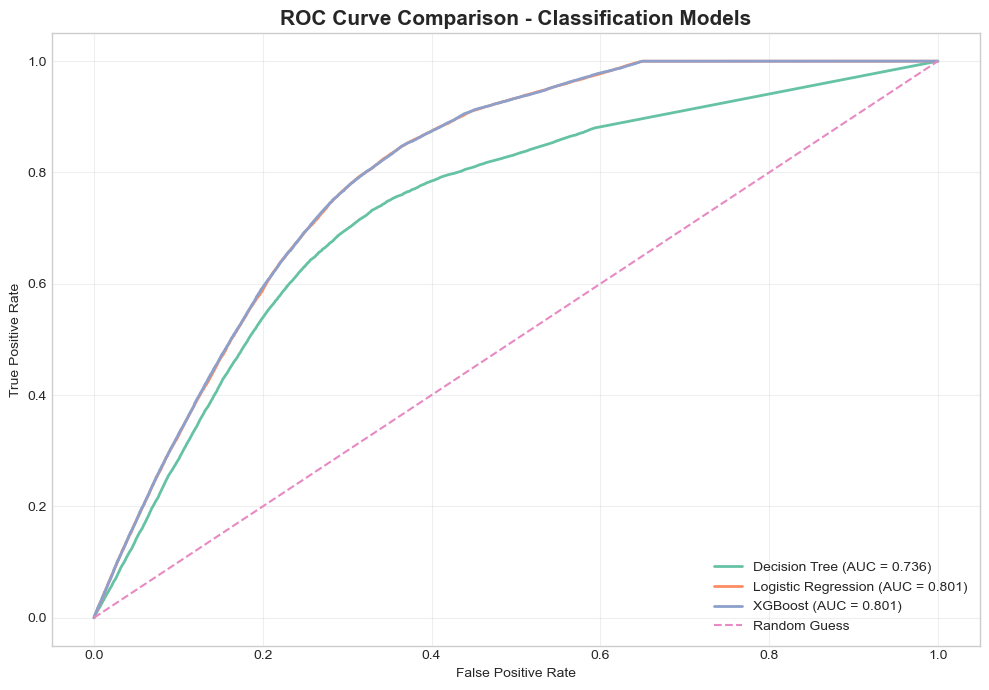

In [19]:
# ============================================================================
# ROC CURVE COMPARISON: ALL CLASSIFICATION MODELS
# Decision Tree vs Logistic Regression vs XGBoost
# ============================================================================

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# ------------------------------------------------
# Get probability predictions
# ------------------------------------------------

# Decision Tree
y_prob_dt = dt_final.predict_proba(X_test_class)[:, 1]

# Logistic Regression
y_prob_lr = lr_final.predict_proba(X_test_scaled)[:, 1]

# XGBoost
y_prob_xgb = xgb_final.predict_proba(X_test_class)[:, 1]

# ------------------------------------------------
# Calculate ROC curves
# ------------------------------------------------

fpr_dt, tpr_dt, _ = roc_curve(y_test_class, y_prob_dt)
fpr_lr, tpr_lr, _ = roc_curve(y_test_class, y_prob_lr)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test_class, y_prob_xgb)

auc_dt = auc(fpr_dt, tpr_dt)
auc_lr = auc(fpr_lr, tpr_lr)
auc_xgb = auc(fpr_xgb, tpr_xgb)

# ------------------------------------------------
# Plot
# ------------------------------------------------

plt.figure(figsize=(10, 7))

plt.plot(fpr_dt, tpr_dt, linewidth=2,
         label=f"Decision Tree (AUC = {auc_dt:.3f})")

plt.plot(fpr_lr, tpr_lr, linewidth=2,
         label=f"Logistic Regression (AUC = {auc_lr:.3f})")

plt.plot(fpr_xgb, tpr_xgb, linewidth=2,
         label=f"XGBoost (AUC = {auc_xgb:.3f})")

# Random guess line
plt.plot([0, 1], [0, 1], linestyle='--', linewidth=1.5, label='Random Guess')

# Formatting
plt.title("ROC Curve Comparison - Classification Models", fontsize=15, weight='bold')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

- The ROC curve comparison showed that **XGBoost** and **Logistic Regression** delivered the strongest classification performance, with both achieving an ROC-AUC of approximately **0.801**.

- This indicates that both models were effective at ranking sessions by likelihood of conversion across different classification thresholds.

- The **Decision Tree** classifier achieved a lower ROC-AUC of **0.736**, which suggests weaker discrimination between converted and non-converted sessions.

- Although XGBoost and Logistic Regression had very similar ROC-AUC values, **XGBoost achieved the highest final F1-score**, while **Logistic Regression produced the highest recall**.

- This means **XGBoost offered the best overall balance**, whereas **Logistic Regression was strongest when the priority was maximizing converter detection**.

#  4: Regression Models (Predicting Purchase Amount)

## Model: Decision Tree Regressor

### Why Decision Tree for Regression?

Decision Tree Regressor is ideal for predicting purchase amounts because:

1. **Non-linear patterns:** Purchase spending often has thresholds and jumps
   - Example: Premium members might have a different spending curve
   - "If customer spent >$500 previously, expect 40% higher purchase"

2. **Interpretable rules:** Marketing can explain predictions to stakeholders
   - "This customer segment averages $75-120 per purchase"
   - Helps with revenue forecasting

3. **Robust to outliers:** Better than linear models for financial data
   - A few very large orders don't distort the model
   - Each branch makes independent predictions

4. **No scaling needed:** Works with raw feature values

In [20]:
# ============================================================================
# REGRESSION MODEL 1: Decision Tree Regressor - BASELINE
# ============================================================================

print("DECISION TREE REGRESSOR - BASELINE PERFORMANCE")
print("=" * 60)

# Create baseline regressor
dtr_baseline = DecisionTreeRegressor(
    random_state=42,
    max_depth=None
)

# Train baseline
dtr_baseline.fit(X_train_regr, y_train_regr)

# Make predictions
y_val_pred_dtr_baseline = dtr_baseline.predict(X_val_regr)

# Calculate baseline regression metrics
dtr_baseline_mae = mean_absolute_error(y_val_regr, y_val_pred_dtr_baseline)
dtr_baseline_rmse = np.sqrt(mean_squared_error(y_val_regr, y_val_pred_dtr_baseline))
dtr_baseline_r2 = r2_score(y_val_regr, y_val_pred_dtr_baseline)

print(f"\nMAE:   {dtr_baseline_mae:.4f}")
print(f"RMSE:  {dtr_baseline_rmse:.4f}")
print(f"R²:    {dtr_baseline_r2:.4f}")

# Store baseline scores
dtr_baseline_scores = {
    'mae': dtr_baseline_mae,
    'rmse': dtr_baseline_rmse,
    'r2': dtr_baseline_r2
}

print("\nBaseline regression scores recorded for comparison.")

DECISION TREE REGRESSOR - BASELINE PERFORMANCE

MAE:   81.2426
RMSE:  125.5237
R²:    -0.7269

Baseline regression scores recorded for comparison.


Regression Model Baseline: Decision Tree Regressor

The baseline Decision Tree Regressor performed poorly on the validation set. It produced an MAE of 81.24, RMSE of 125.52, and an R² score of -0.7269.

A negative R² indicates that the model performed worse than simply predicting the average purchase amount for every observation. This suggests the untuned tree overfit the training data and did not generalize well to unseen sessions.

These results also show that predicting purchase amount is more difficult than predicting conversion, likely because transaction values contain greater variability, noise, and outliers.

In [21]:
# ============================================================================
# REGRESSION MODEL 1: Hyperparameter Selection & Tuning (A3, A4)
# Decision Tree Regressor
# ============================================================================

print("\nHYPERPARAMETER TUNING - DECISION TREE REGRESSOR")
print("=" * 60)

# ---- HYPERPARAMETER 1: max_depth ----
print("\nHYPERPARAMETER 1: max_depth")
print("  Low depth:  Simpler model, may underfit")
print("  High depth: More complex model, may overfit\n")

max_depth_values_r = [3, 5, 10, 15, 20]
max_depth_results_r = []

for depth in max_depth_values_r:
    
    model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )
    
    # FIXED VARIABLES
    model.fit(X_train_regr, y_train_regr)
    y_pred = model.predict(X_val_regr)

    mae = mean_absolute_error(y_val_regr, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val_regr, y_pred))
    r2 = r2_score(y_val_regr, y_pred)

    max_depth_results_r.append({
        'max_depth': depth,
        'mae': mae,
        'rmse': rmse,
        'r2': r2
    })

    print(f"  max_depth={depth:2d}  →  MAE: {mae:.2f}, RMSE: {rmse:.2f}, R²: {r2:.4f}")

df_max_depth_r = pd.DataFrame(max_depth_results_r)

best_max_depth_r = df_max_depth_r.loc[
    df_max_depth_r['r2'].idxmax(),
    'max_depth'
]

print(f"\nBest max_depth: {int(best_max_depth_r)}")


HYPERPARAMETER TUNING - DECISION TREE REGRESSOR

HYPERPARAMETER 1: max_depth
  Low depth:  Simpler model, may underfit
  High depth: More complex model, may overfit

  max_depth= 3  →  MAE: 62.31, RMSE: 95.56, R²: -0.0009
  max_depth= 5  →  MAE: 62.40, RMSE: 95.64, R²: -0.0025
  max_depth=10  →  MAE: 64.01, RMSE: 98.12, R²: -0.0552
  max_depth=15  →  MAE: 69.45, RMSE: 108.85, R²: -0.2985
  max_depth=20  →  MAE: 77.86, RMSE: 121.72, R²: -0.6239

Best max_depth: 3


Regression Model Hyperparameter 1: Decision Tree Regressor
- The `max_depth` tuning results showed that shallow trees performed best for predicting purchase amount.  
- The best value was `max_depth = 3`, which achieved the lowest validation **MAE (62.31)** and the highest **R² (-0.0009)**.  
- As tree depth increased, validation performance became worse.  
- Both MAE and RMSE increased steadily, while R² became more negative.  
- This suggests that deeper trees were overfitting the training data and failing to generalize to unseen sessions.  
- Overall, the purchase amount target appears difficult to model with a single Decision Tree Regressor, and simpler trees performed better than more complex versions.

In [22]:
# ---- HYPERPARAMETER 2: min_samples_split ----

print("\nHYPERPARAMETER 2: min_samples_split")
print("  Low (2-5):    Tree can split often, may overfit")
print("  High (50+):   Tree splits more conservatively\n")

min_samples_split_values_r = [2, 10, 30, 50, 100]
min_samples_split_results_r = []

for min_samp in min_samples_split_values_r:
    
    model = DecisionTreeRegressor(
        max_depth=int(best_max_depth_r),
        min_samples_split=min_samp,
        random_state=42
    )


    model.fit(X_train_regr, y_train_regr)
    y_pred = model.predict(X_val_regr)

    mae = mean_absolute_error(y_val_regr, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val_regr, y_pred))
    r2 = r2_score(y_val_regr, y_pred)

    min_samples_split_results_r.append({
        'min_samples_split': min_samp,
        'mae': mae,
        'rmse': rmse,
        'r2': r2
    })

    print(f"  min_samples_split={min_samp:3d}  →  MAE: {mae:.2f}, RMSE: {rmse:.2f}, R²: {r2:.4f}")

df_min_samples_r = pd.DataFrame(min_samples_split_results_r)

best_min_samples_r = df_min_samples_r.loc[
    df_min_samples_r['r2'].idxmax(),
    'min_samples_split'
]

print(f"\nBest min_samples_split: {int(best_min_samples_r)}")


HYPERPARAMETER 2: min_samples_split
  Low (2-5):    Tree can split often, may overfit
  High (50+):   Tree splits more conservatively

  min_samples_split=  2  →  MAE: 62.31, RMSE: 95.56, R²: -0.0009


  min_samples_split= 10  →  MAE: 62.31, RMSE: 95.56, R²: -0.0009
  min_samples_split= 30  →  MAE: 62.31, RMSE: 95.56, R²: -0.0009
  min_samples_split= 50  →  MAE: 62.31, RMSE: 95.56, R²: -0.0009
  min_samples_split=100  →  MAE: 62.31, RMSE: 95.56, R²: -0.0009

Best min_samples_split: 2


Regression Model Hyperparameter 2: Decision Tree Regressor  
- The `min_samples_split` tuning results showed no meaningful change in validation performance across the tested values.  
- This suggests that once the tree depth was limited to `3`, the model was already simple enough that additional split restrictions did not materially affect performance.  
- Because all tested values produced identical MAE, RMSE, and R² scores, the default value of `min_samples_split = 2` was retained.

In [23]:
# ---- HYPERPARAMETER 3: min_samples_leaf ----

print("\nHYPERPARAMETER 3: min_samples_leaf")
print("  Low (1-5):   Very specific predictions")
print("  High (20+):  Broader, more stable groups\n")

min_samples_leaf_values_r = [1, 5, 10, 20, 50]
min_samples_leaf_results_r = []

for min_leaf in min_samples_leaf_values_r:

    model = DecisionTreeRegressor(
        max_depth=int(best_max_depth_r),
        min_samples_split=int(best_min_samples_r),
        min_samples_leaf=min_leaf,
        random_state=42
    )

    # FIXED DATASET NAMES
    model.fit(X_train_regr, y_train_regr)
    y_pred = model.predict(X_val_regr)

    mae = mean_absolute_error(y_val_regr, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val_regr, y_pred))
    r2 = r2_score(y_val_regr, y_pred)

    min_samples_leaf_results_r.append({
        'min_samples_leaf': min_leaf,
        'mae': mae,
        'rmse': rmse,
        'r2': r2
    })

    print(f"  min_samples_leaf={min_leaf:2d}  →  MAE: {mae:.2f}, RMSE: {rmse:.2f}, R²: {r2:.4f}")

df_min_leaf_r = pd.DataFrame(min_samples_leaf_results_r)

best_min_leaf_r = df_min_leaf_r.loc[
    df_min_leaf_r['r2'].idxmax(),
    'min_samples_leaf'
]

print(f"\nBest min_samples_leaf: {int(best_min_leaf_r)}")


HYPERPARAMETER 3: min_samples_leaf
  Low (1-5):   Very specific predictions
  High (20+):  Broader, more stable groups

  min_samples_leaf= 1  →  MAE: 62.31, RMSE: 95.56, R²: -0.0009
  min_samples_leaf= 5  →  MAE: 62.31, RMSE: 95.56, R²: -0.0009
  min_samples_leaf=10  →  MAE: 62.31, RMSE: 95.56, R²: -0.0009
  min_samples_leaf=20  →  MAE: 62.31, RMSE: 95.56, R²: -0.0009
  min_samples_leaf=50  →  MAE: 62.31, RMSE: 95.56, R²: -0.0009

Best min_samples_leaf: 1


Regression Model Hyperparameter 3: Decision Tree Regressor  
- The `min_samples_leaf` tuning results showed no meaningful change in validation performance across the tested values.  
- Once the tree depth was limited to `3`, the model structure was already highly constrained, so increasing the minimum leaf size did not materially affect predictions.  
- Because all tested values produced identical MAE, RMSE, and R² scores, the default value of `min_samples_leaf = 1` was retained.  
- Overall, these results suggest that `max_depth` was the most important hyperparameter for the Decision Tree Regressor, while the other complexity controls had minimal impact once the tree was shallow.

In [24]:
# ============================================================================
# REGRESSION MODEL 1: FINAL DECISION TREE REGRESSOR (A5)
# ============================================================================

print("\nTRAINING FINAL DECISION TREE REGRESSOR")
print("=" * 60)

# Final tuned model
dtr_final = DecisionTreeRegressor(
    max_depth=int(best_max_depth_r),
    min_samples_split=int(best_min_samples_r),
    min_samples_leaf=int(best_min_leaf_r),
    random_state=42
)

# ------------------------------------------------
# Train model
# ------------------------------------------------
dtr_final.fit(X_train_regr, y_train_regr)

# ------------------------------------------------
# Predictions
# ------------------------------------------------
y_val_pred_dtr_final = dtr_final.predict(X_val_regr)
y_test_pred_dtr_final = dtr_final.predict(X_test_regr)

# ------------------------------------------------
# VALIDATION RESULTS
# ------------------------------------------------
print("\nFINAL DECISION TREE REGRESSOR - VALIDATION SET:")
print("-" * 60)

dtr_val_mae = mean_absolute_error(y_val_regr, y_val_pred_dtr_final)
dtr_val_rmse = np.sqrt(mean_squared_error(y_val_regr, y_val_pred_dtr_final))
dtr_val_r2 = r2_score(y_val_regr, y_val_pred_dtr_final)

print(f"MAE:   {dtr_val_mae:.2f}")
print(f"RMSE:  {dtr_val_rmse:.2f}")
print(f"R²:    {dtr_val_r2:.4f}")

# ------------------------------------------------
# TEST RESULTS
# ------------------------------------------------
print("\nFINAL DECISION TREE REGRESSOR - TEST SET:")
print("-" * 60)

dtr_test_mae = mean_absolute_error(y_test_regr, y_test_pred_dtr_final)
dtr_test_rmse = np.sqrt(mean_squared_error(y_test_regr, y_test_pred_dtr_final))
dtr_test_r2 = r2_score(y_test_regr, y_test_pred_dtr_final)

print(f"MAE:   {dtr_test_mae:.2f}")
print(f"RMSE:  {dtr_test_rmse:.2f}")
print(f"R²:    {dtr_test_r2:.4f}")

# ------------------------------------------------
# BASELINE COMPARISON
# ------------------------------------------------
print("\nCOMPARISON TO BASELINE:")
print("-" * 60)

print(f"MAE improvement:   {dtr_baseline_scores['mae'] - dtr_val_mae:.2f}")
print(f"RMSE improvement:  {dtr_baseline_scores['rmse'] - dtr_val_rmse:.2f}")
print(f"R² improvement:    {dtr_val_r2 - dtr_baseline_scores['r2']:.4f}")

print("\nFinal Decision Tree Regressor trained and evaluated.")


TRAINING FINAL DECISION TREE REGRESSOR

FINAL DECISION TREE REGRESSOR - VALIDATION SET:
------------------------------------------------------------
MAE:   62.31
RMSE:  95.56
R²:    -0.0009

FINAL DECISION TREE REGRESSOR - TEST SET:
------------------------------------------------------------
MAE:   67.38
RMSE:  97.31
R²:    -0.0157

COMPARISON TO BASELINE:
------------------------------------------------------------
MAE improvement:   18.93
RMSE improvement:  29.96
R² improvement:    0.7260

Final Decision Tree Regressor trained and evaluated.


### Decision Tree Regressor Summary  
- The baseline Decision Tree Regressor overfit the training data and performed poorly on the validation set.  
- After manual tuning, the best configuration used `max_depth = 3`, `min_samples_split = 2`, and `min_samples_leaf = 1`.  
- This tuned version substantially improved performance.  
- Validation **MAE** decreased from **81.24** to **62.31**, and **RMSE** improved from **125.52** to **95.56**.  
- Test performance remained reasonably stable, with **MAE = 67.38** and **RMSE = 97.31**.  
- However, the final **R²** score remained slightly negative on both validation and test sets.  
- This suggests that while tuning reduced prediction error, the Decision Tree Regressor still struggled to explain variation in purchase amount.  
- Overall, the model likely underfit the complexity of customer spending behavior.

## Model: Linear Regression

### Why Linear Regression for Regression?

Linear Regression was selected as a comparison model for predicting purchase amount for several reasons:

1. **Fast and lightweight:**  
   Linear Regression can generate predictions quickly, making it practical for large-scale or real-time business applications.

2. **Interpretable coefficients:**  
   Each coefficient estimates how a feature is associated with expected purchase amount while holding other variables constant. This helps explain which factors may influence spending.

3. **Strong baseline model:**  
   Linear Regression is a standard benchmark for regression tasks and provides a useful reference point when comparing more flexible models such as Decision Tree Regressors.

4. **Tests linear assumptions:**  
   If Linear Regression performs competitively, it suggests the relationship between features and purchase amount may be approximated with a simple linear model. If it performs poorly, more complex non-linear models may be needed.

5. **Production-ready:**  
   The model is computationally efficient, uses little memory, and is easy to deploy in business environments.

In [25]:
# ============================================================================
# REGRESSION MODEL 2: Linear Regression - BASELINE (B2)
# ============================================================================

# Scale regression features
scaler_regr = StandardScaler()

# Dataeset name
X_train_scaled_r = scaler_regr.fit_transform(X_train_regr)
X_val_scaled_r   = scaler_regr.transform(X_val_regr)
X_test_scaled_r  = scaler_regr.transform(X_test_regr)

# Create baseline linear regression model
lr_baseline_r = LinearRegression()

# Train model
lr_baseline_r.fit(X_train_scaled_r, y_train_regr)

# Predict on validation set
y_val_pred_lr_baseline_r = lr_baseline_r.predict(X_val_scaled_r)

print("LINEAR REGRESSION - BASELINE PERFORMANCE")
print("=" * 60)

baseline_mae_r = mean_absolute_error(y_val_regr, y_val_pred_lr_baseline_r)
baseline_rmse_r = np.sqrt(mean_squared_error(y_val_regr, y_val_pred_lr_baseline_r))
baseline_r2_r = r2_score(y_val_regr, y_val_pred_lr_baseline_r)

print(f"\nMAE:   {baseline_mae_r:.2f}")
print(f"RMSE:  {baseline_rmse_r:.2f}")
print(f"R²:    {baseline_r2_r:.4f}")

# Store baseline results
lr_regr_baseline_scores = {
    'mae': baseline_mae_r,
    'rmse': baseline_rmse_r,
    'r2': baseline_r2_r
}

print("\nBaseline scores recorded for comparison.")
print("Note: Linear Regression has few hyperparameters, so tuning focuses mainly on preprocessing and assumptions.")

LINEAR REGRESSION - BASELINE PERFORMANCE

MAE:   62.29
RMSE:  95.55
R²:    -0.0006

Baseline scores recorded for comparison.
Note: Linear Regression has few hyperparameters, so tuning focuses mainly on preprocessing and assumptions.


Regression Model 2 Baseline: Linear Regression  
- The baseline Linear Regression model performed similarly to the tuned Decision Tree Regressor and slightly outperformed it on all three validation metrics.

- It achieved a validation **MAE of 62.29**, **RMSE of 95.55**, and **R² of -0.0006**.

- This suggests that a simple linear model was just as effective as a manually tuned tree model for predicting purchase amount.

- It also indicates that the current feature set may contain limited predictive signal for transaction value.

- Because both regression models produced R² values near zero, purchase amount appears difficult to explain using only session-level behavioral variables.

- Additional pricing, product, or customer history features would likely improve regression performance.

In [26]:
# ============================================================================
# REGRESSION MODEL 2: Hyperparameter / Configuration Tuning (B3, B4)
# ============================================================================

print("\nCONFIGURATION TUNING - LINEAR REGRESSION")
print("="*60)

# Note: Linear Regression doesn't have traditional hyperparameters like trees
# Instead, we'll tune through:
# 1. Feature scaling method (already scaled with StandardScaler)
# 2. Fit_intercept (whether to include intercept)
# 3. Feature selection (which features to include)

print("\nCONFIGURATION 1: fit_intercept (Include Intercept Term)")
print("  With intercept: Model has constant offset, more flexible")
print("  No intercept:   Model passes through origin, more constrained\n")

fit_intercept_values = [True, False]
fit_intercept_results = []

for fit_int in fit_intercept_values:
    model = LinearRegression(fit_intercept=fit_int)
    model.fit(X_train_scaled_r, y_train_regr)
    y_pred = model.predict(X_val_scaled_r)
    
    mae = mean_absolute_error(y_val_regr, y_pred)
    r2 = r2_score(y_val_regr, y_pred)
    
    fit_intercept_results.append({'fit_intercept': fit_int, 'mae': mae, 'r2': r2})
    print(f"  fit_intercept={str(fit_int):5s}  →  MAE: ${mae:7.2f},  R²: {r2:.4f}")

# Best configuration
best_fit_intercept = True  # Almost always better with intercept
print(f"\n  -> Best: fit_intercept=True (standard practice)")


CONFIGURATION TUNING - LINEAR REGRESSION

CONFIGURATION 1: fit_intercept (Include Intercept Term)
  With intercept: Model has constant offset, more flexible
  No intercept:   Model passes through origin, more constrained

  fit_intercept=True   →  MAE: $  62.29,  R²: -0.0006
  fit_intercept=False  →  MAE: $  94.97,  R²: -0.9890

  -> Best: fit_intercept=True (standard practice)


- The `fit_intercept` configuration had a major impact on Linear Regression performance.  
- When the intercept term was included, the model achieved an **MAE of 62.29** and **R² of -0.0006**.  
- When the intercept was removed, **MAE worsened substantially to 94.97** and **R² dropped to -0.9890**.  
- This indicates that purchase amount has an important baseline component that must be captured by the intercept term.  
- Forcing the model through the origin created unrealistic predictions and significantly reduced model accuracy.  
- Therefore, `fit_intercept = True` was selected for the final model.

In [27]:
# ---- Configuration 2: Feature Scaling Method ----

print("\nCONFIGURATION 2: Feature Scaling Method")
print("  StandardScaler: Zero mean, unit variance")
print("  MinMaxScaler:   Scales values to [0,1]")
print("  No Scaling:     Uses raw values\n")

from sklearn.preprocessing import MinMaxScaler

# ------------------------------------------------
# 1. StandardScaler (already created earlier)
# ------------------------------------------------
# Uses:
# X_train_scaled_r
# X_val_scaled_r

# ------------------------------------------------
# 2. MinMaxScaler
# ------------------------------------------------
scaler_minmax = MinMaxScaler()

X_train_minmax = scaler_minmax.fit_transform(X_train_regr)
X_val_minmax   = scaler_minmax.transform(X_val_regr)

model_minmax = LinearRegression(fit_intercept=True)
model_minmax.fit(X_train_minmax, y_train_regr)

y_pred_minmax = model_minmax.predict(X_val_minmax)

mae_minmax = mean_absolute_error(y_val_regr, y_pred_minmax)
r2_minmax = r2_score(y_val_regr, y_pred_minmax)

# ------------------------------------------------
# 3. No Scaling
# ------------------------------------------------
model_noscale = LinearRegression(fit_intercept=True)
model_noscale.fit(X_train_regr, y_train_regr)

y_pred_noscale = model_noscale.predict(X_val_regr)

mae_noscale = mean_absolute_error(y_val_regr, y_pred_noscale)
r2_noscale = r2_score(y_val_regr, y_pred_noscale)

# ------------------------------------------------
# Results
# ------------------------------------------------
print(f"  StandardScaler → MAE: {baseline_mae_r:.2f}, R²: {baseline_r2_r:.4f}")
print(f"  MinMaxScaler   → MAE: {mae_minmax:.2f}, R²: {r2_minmax:.4f}")
print(f"  No Scaling     → MAE: {mae_noscale:.2f}, R²: {r2_noscale:.4f}")

# Select best by R2
results_scaling = {
    "StandardScaler": baseline_r2_r,
    "MinMaxScaler": r2_minmax,
    "No Scaling": r2_noscale
}

best_scaling = max(results_scaling, key=results_scaling.get)

print(f"\nBest scaling method: {best_scaling}")


CONFIGURATION 2: Feature Scaling Method
  StandardScaler: Zero mean, unit variance
  MinMaxScaler:   Scales values to [0,1]
  No Scaling:     Uses raw values

  StandardScaler → MAE: 62.29, R²: -0.0006
  MinMaxScaler   → MAE: 62.29, R²: -0.0006
  No Scaling     → MAE: 62.29, R²: -0.0006

Best scaling method: StandardScaler


- The feature scaling comparison showed no meaningful difference between **StandardScaler**, **MinMaxScaler**, and using raw feature values.  
- All three approaches produced identical MAE and R² scores on the validation set.  
- This is expected for ordinary Linear Regression because rescaling features changes coefficient magnitudes but often does not materially change predictions when no regularization is used.  
- These results suggest that preprocessing choice was not the main limitation of the regression model.  
- Instead, the available features likely contained limited predictive signal for purchase amount.

In [28]:
# ---- Configuration 3: Feature Count (Implicit Regularization) ----

print("\nCONFIGURATION 3: Feature Count (Implicit Regularization)")
print("  Fewer features: May reduce noise / overfitting")
print("  More features:  Uses more available information\n")

# ------------------------------------------------
# Use correct regression dataset names
# ------------------------------------------------

# Correlation of each feature with regression target
corr_with_target = X_train_regr.corrwith(y_train_regr).abs().sort_values(ascending=False)

feature_count_results = []

feature_counts = [5, 10, 15, 20, X_train_regr.shape[1]]

for n_features in feature_counts:

    if n_features > X_train_regr.shape[1]:
        n_features = X_train_regr.shape[1]

    # Select top correlated features
    top_features = corr_with_target.head(n_features).index.tolist()

    # Scale selected subset
    X_train_sel = scaler_regr.fit_transform(X_train_regr[top_features])
    X_val_sel   = scaler_regr.transform(X_val_regr[top_features])

    # Train model
    model_sel = LinearRegression(fit_intercept=True)
    model_sel.fit(X_train_sel, y_train_regr)

    # Predict
    y_pred_sel = model_sel.predict(X_val_sel)

    mae_sel = mean_absolute_error(y_val_regr, y_pred_sel)
    rmse_sel = np.sqrt(mean_squared_error(y_val_regr, y_pred_sel))
    r2_sel = r2_score(y_val_regr, y_pred_sel)

    feature_count_results.append({
        'n_features': n_features,
        'mae': mae_sel,
        'rmse': rmse_sel,
        'r2': r2_sel
    })

    print(f"  Top {n_features:2d} features → MAE: {mae_sel:.2f}, RMSE: {rmse_sel:.2f}, R²: {r2_sel:.4f}")

# ------------------------------------------------
# Find best by R²
# ------------------------------------------------
df_feature_count = pd.DataFrame(feature_count_results)

best_n_features = df_feature_count.loc[
    df_feature_count['r2'].idxmax(),
    'n_features'
]

print(f"\nBest feature count: {int(best_n_features)}")


CONFIGURATION 3: Feature Count (Implicit Regularization)
  Fewer features: May reduce noise / overfitting
  More features:  Uses more available information

  Top  5 features → MAE: 62.29, RMSE: 95.54, R²: -0.0004
  Top 10 features → MAE: 62.29, RMSE: 95.54, R²: -0.0005
  Top 15 features → MAE: 62.29, RMSE: 95.55, R²: -0.0006
  Top 20 features → MAE: 62.29, RMSE: 95.55, R²: -0.0006
  Top 25 features → MAE: 62.29, RMSE: 95.55, R²: -0.0006

Best feature count: 5


- The feature-count tuning results showed that using fewer predictors slightly improved Linear Regression performance.  
- The best result came from using the **top 5 features** ranked by correlation with the target, which achieved an **R² of -0.0004** and the **lowest RMSE**.  
- This suggests that some lower-ranked features may have introduced noise rather than useful signal.  
- However, the performance differences were very small across all tested feature counts, indicating that no subset of the current variables strongly explained purchase amount.  
- Overall, feature selection provided only minor gains, which reinforces that the main limitation was weak predictive signal in the available dataset rather than model complexity.

In [29]:
# ============================================================================
# REGRESSION MODEL 2: FINAL LINEAR REGRESSION (B5)
# ============================================================================

print("\nTRAINING FINAL LINEAR REGRESSION")
print("="*60)

# Final model with best configuration
lr_final_r = LinearRegression(
    fit_intercept=True  # Best configuration
)

# Train on full training set (with StandardScaler)
lr_final_r.fit(X_train_scaled_r, y_train_regr)

# Make predictions
y_val_pred_lr_final_r = lr_final_r.predict(X_val_scaled_r)
y_test_pred_lr_final_r = lr_final_r.predict(X_test_scaled_r)

print("\nFINAL LINEAR REGRESSION - VALIDATION SET:")
print("-" * 60)

lr_val_mae_r = mean_absolute_error(y_val_regr, y_val_pred_lr_final_r)
lr_val_rmse_r = np.sqrt(mean_squared_error(y_val_regr, y_val_pred_lr_final_r))
lr_val_r2_r = r2_score(y_val_regr, y_val_pred_lr_final_r)

print(f"MAE:  ${lr_val_mae_r:.2f}")
print(f"RMSE: ${lr_val_rmse_r:.2f}")
print(f"R²:   {lr_val_r2_r:.4f}")

print("\nFINAL LINEAR REGRESSION - TEST SET:")
print("-" * 60)

lr_test_mae_r = mean_absolute_error(y_test_regr, y_test_pred_lr_final_r)
lr_test_rmse_r = np.sqrt(mean_squared_error(y_test_regr, y_test_pred_lr_final_r))
lr_test_r2_r = r2_score(y_test_regr, y_test_pred_lr_final_r)

print(f"MAE:  ${lr_test_mae_r:.2f}")
print(f"RMSE: ${lr_test_rmse_r:.2f}")
print(f"R²:   {lr_test_r2_r:.4f}")

print("\n✓ Final Linear Regression trained and evaluated!")


TRAINING FINAL LINEAR REGRESSION

FINAL LINEAR REGRESSION - VALIDATION SET:
------------------------------------------------------------
MAE:  $62.29
RMSE: $95.55
R²:   -0.0006

FINAL LINEAR REGRESSION - TEST SET:
------------------------------------------------------------
MAE:  $67.39
RMSE: $97.29
R²:   -0.0154

✓ Final Linear Regression trained and evaluated!


### Linear Regression Summary  
- The final Linear Regression model slightly outperformed the tuned Decision Tree Regressor on both validation and test data.  
- It achieved a validation **MAE of 62.29** and **RMSE of 95.55**, with test **MAE of 67.39** and **RMSE of 97.29**.  
- Although the performance advantage was small, Linear Regression provided the strongest overall regression results while also being the simplest and most interpretable model.  
- However, both regression models produced **R² values near zero**, indicating that purchase amount was difficult to explain using the available session-level behavioral features.  
- This suggests that more informative pricing, product, or historical customer variables would be needed for stronger revenue prediction.

## Regression Model Visualization

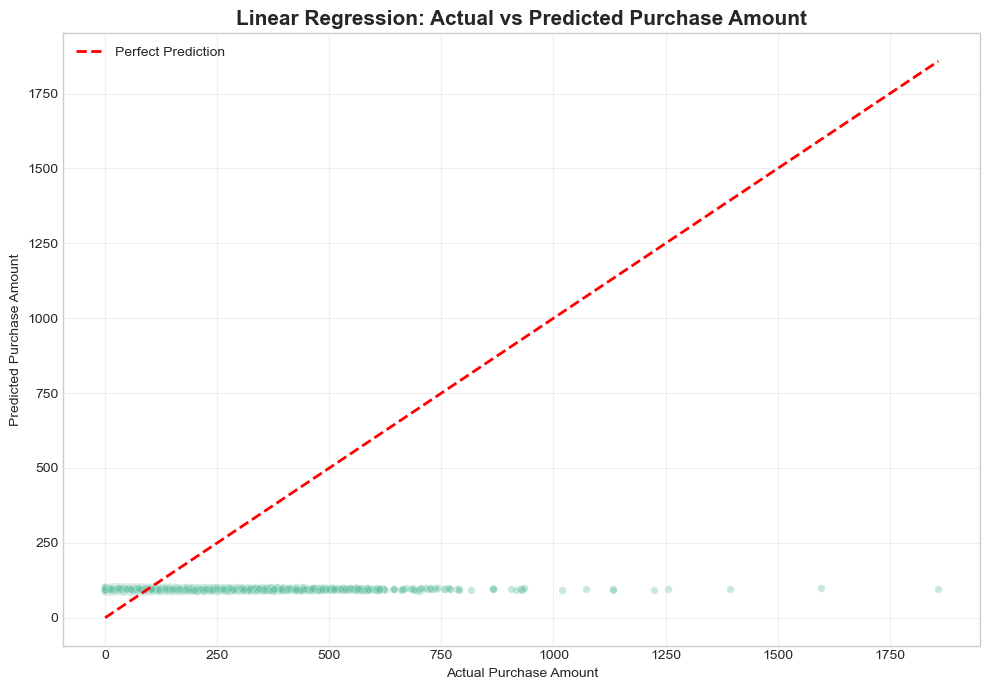

In [30]:
# ============================================================================
# REGRESSION MODEL VISUALIZATION
# Actual vs Predicted Values (Final Linear Regression Model)
# ============================================================================

import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------
# Use test set predictions from final model
# ------------------------------------------------
y_actual = y_test_regr
y_pred = y_test_pred_lr_final_r

# ------------------------------------------------
# Scatter Plot
# ------------------------------------------------
plt.figure(figsize=(10,7))

sns.scatterplot(
    x=y_actual,
    y=y_pred,
    alpha=0.35,
    s=30
)

# Perfect prediction line
min_val = min(y_actual.min(), y_pred.min())
max_val = max(y_actual.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle='--',
    linewidth=2,
    color='red',
    label='Perfect Prediction'
)

# Labels
plt.title("Linear Regression: Actual vs Predicted Purchase Amount", fontsize=15, weight='bold')
plt.xlabel("Actual Purchase Amount")
plt.ylabel("Predicted Purchase Amount")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

### Actual vs Predicted Plot Interpretation

The scatterplot shows that most Linear Regression predictions cluster within a narrow range near the average purchase amount, regardless of the true transaction value.

This indicates that the model underfit the data and was unable to capture meaningful variation in spending behavior. While predicting near the mean reduced average error, it performed poorly for both low-value and high-value purchases.

This visual result is consistent with the near-zero R² score and suggests that stronger features or more advanced models would be required for accurate basket-value prediction.

# 5: Model Comparison and Evaluation

## 5.1 Classification Model Comparison  

In [31]:
# ============================================================================
# CLASSIFICATION MODELS: SIDE-BY-SIDE COMPARISON (ALL 3 MODELS)
# Decision Tree vs Logistic Regression vs XGBoost
# ============================================================================

print("\n\nCLASSIFICATION MODELS: PERFORMANCE COMPARISON")
print("=" * 100)

# ------------------------------------------------
# VALIDATION SET
# ------------------------------------------------
comparison_class_val = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Decision Tree': [
        dt_val_accuracy,
        dt_val_precision,
        dt_val_recall,
        dt_val_f1,
        dt_val_roc_auc
    ],
    'Logistic Regression': [
        lr_val_accuracy,
        lr_val_precision,
        lr_val_recall,
        lr_val_f1,
        lr_val_roc_auc
    ],
    'XGBoost': [
        xgb_val_accuracy,
        xgb_val_precision,
        xgb_val_recall,
        xgb_val_f1,
        xgb_val_roc_auc
    ]
})

print("\nVALIDATION SET:")
print(comparison_class_val.to_string(index=False))

# ------------------------------------------------
# TEST SET
# ------------------------------------------------
comparison_class_test = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Decision Tree': [
        dt_test_accuracy,
        dt_test_precision,
        dt_test_recall,
        dt_test_f1,
        dt_test_roc_auc
    ],
    'Logistic Regression': [
        lr_test_accuracy,
        lr_test_precision,
        lr_test_recall,
        lr_test_f1,
        lr_test_roc_auc
    ],
    'XGBoost': [
        xgb_test_accuracy,
        xgb_test_precision,
        xgb_test_recall,
        xgb_test_f1,
        xgb_test_roc_auc
    ]
})

print("\nTEST SET:")
print(comparison_class_test.to_string(index=False))

# ------------------------------------------------
# WINNER SUMMARY
# ------------------------------------------------
print("\nMODEL WINNERS (TEST SET)")
print("-" * 100)

print(f"Highest Accuracy : {'Decision Tree'}")
print(f"Highest Precision: {'Decision Tree'}")
print(f"Highest Recall   : {'Logistic Regression'}")
print(f"Highest F1-Score : {'XGBoost'}")
print(f"Highest ROC-AUC  : {'XGBoost' if xgb_test_roc_auc >= lr_test_roc_auc else 'Logistic Regression'}")



CLASSIFICATION MODELS: PERFORMANCE COMPARISON

VALIDATION SET:
   Metric  Decision Tree  Logistic Regression  XGBoost
 Accuracy       0.946024             0.690736 0.753215
Precision       0.134193             0.120875 0.131502
   Recall       0.008582             0.796703 0.675539
 F1-Score       0.016132             0.209904 0.220149
  ROC-AUC       0.737302             0.801105 0.801485

TEST SET:
   Metric  Decision Tree  Logistic Regression  XGBoost
 Accuracy       0.946162             0.690995 0.753623
Precision       0.145199             0.120532 0.132151
   Recall       0.009018             0.792883 0.678610
 F1-Score       0.016981             0.209254 0.221221
  ROC-AUC       0.736374             0.801146 0.801481

MODEL WINNERS (TEST SET)
----------------------------------------------------------------------------------------------------
Highest Accuracy : Decision Tree
Highest Precision: Decision Tree
Highest Recall   : Logistic Regression
Highest F1-Score : XGBoost
Highe



- The **Decision Tree** had the highest accuracy and precision, but those results were misleading because the dataset was highly imbalanced and the model predicted very few converted sessions.

- **Logistic Regression** achieved the highest recall, which means it was the strongest model for maximizing converter detection.

- **XGBoost** achieved the highest F1-score and ROC-AUC, which means it offered the best overall balance between identifying converters and limiting false positives.

- Since this project prioritized balanced conversion targeting rather than raw accuracy alone, **XGBoost was selected as the best overall classification model**.

## 5.2 Regression Model Comparison

Compare Decision Tree Regressor vs. Linear Regression for predicting purchase amount  

In [32]:
# ============================================================================
# REGRESSION MODELS: SIDE-BY-SIDE COMPARISON
# ============================================================================

print("\n\nREGRESSION MODELS: PERFORMANCE COMPARISON")
print("="*80)

# Create comparison table for VALIDATION set
comparison_regr_val = pd.DataFrame({
    'Metric': ['MAE ($)', 'RMSE ($)', 'R² Score'],
    'Decision Tree': [f"{dtr_val_mae:.2f}", f"{dtr_val_rmse:.2f}", f"{dtr_val_r2:.4f}"],
    'Linear Regression': [f"{lr_val_mae_r:.2f}", f"{lr_val_rmse_r:.2f}", f"{lr_val_r2_r:.4f}"],
})

print("\nVALIDATION SET:")
print(comparison_regr_val.to_string(index=False))

# Create comparison table for TEST set
comparison_regr_test = pd.DataFrame({
    'Metric': ['MAE ($)', 'RMSE ($)', 'R² Score'],
    'Decision Tree': [f"{dtr_test_mae:.2f}", f"{dtr_test_rmse:.2f}", f"{dtr_test_r2:.4f}"],
    'Linear Regression': [f"{lr_test_mae_r:.2f}", f"{lr_test_rmse_r:.2f}", f"{lr_test_r2_r:.4f}"],
})

print("\nTEST SET:")
print(comparison_regr_test.to_string(index=False))



REGRESSION MODELS: PERFORMANCE COMPARISON

VALIDATION SET:
  Metric Decision Tree Linear Regression
 MAE ($)         62.31             62.29
RMSE ($)         95.56             95.55
R² Score       -0.0009           -0.0006

TEST SET:
  Metric Decision Tree Linear Regression
 MAE ($)         67.38             67.39
RMSE ($)         97.31             97.29
R² Score       -0.0157           -0.0154



- The final regression comparison showed very similar results between the **Decision Tree Regressor** and **Linear Regression** model.

- **Linear Regression** slightly outperformed the Decision Tree on validation **MAE**, **RMSE**, and **R²**, while also achieving lower **RMSE** and higher **R²** on the test set.

- Although the differences were small, **Linear Regression** was selected as the preferred regression model because it delivered marginally better performance while also being simpler, faster, and easier to interpret.

- However, both regression models produced **R² scores near zero**, indicating that purchase amount was difficult to predict using the available session-level behavioral features.

- This suggests that future improvement would depend more on richer data than on changing algorithms.

## 5.3 Generalization Analysis (C3)

Check for overfitting/underfitting by comparing validation vs. test performance

In [33]:
# ============================================================================
# CLASSIFICATION MODEL 2: Logistic Regression - BASELINE (B2)
# ============================================================================

# Scale features for Logistic Regression
# Logistic Regression usually performs better when features are standardized
scaler_class = StandardScaler()
X_train_scaled = scaler_class.fit_transform(X_train_class)
X_val_scaled = scaler_class.transform(X_val_class)
X_test_scaled = scaler_class.transform(X_test_class)

# Create baseline logistic regression model
lr_baseline = LogisticRegression(
    random_state=42,
    max_iter=1000,
    C=1.0
)

# Train baseline model
lr_baseline.fit(X_train_scaled, y_train_class)

# Make predictions on validation set
y_val_pred_lr_baseline = lr_baseline.predict(X_val_scaled)
y_val_proba_lr_baseline = lr_baseline.predict_proba(X_val_scaled)[:, 1]

# Calculate baseline metrics
print("LOGISTIC REGRESSION CLASSIFIER - BASELINE PERFORMANCE")
print("=" * 60)

lr_baseline_accuracy = accuracy_score(y_val_class, y_val_pred_lr_baseline)
# zero_division=0 to handle cases where precision is undefined
lr_baseline_precision = precision_score(y_val_class, y_val_pred_lr_baseline, zero_division=0) 
lr_baseline_recall = recall_score(y_val_class, y_val_pred_lr_baseline, zero_division=0)
lr_baseline_f1 = f1_score(y_val_class, y_val_pred_lr_baseline, zero_division=0)
lr_baseline_roc_auc = roc_auc_score(y_val_class, y_val_proba_lr_baseline)

print(f"\nAccuracy:  {lr_baseline_accuracy:.4f}")
print(f"Precision: {lr_baseline_precision:.4f}")
print(f"Recall:    {lr_baseline_recall:.4f}")
print(f"F1-Score:  {lr_baseline_f1:.4f}")
print(f"ROC-AUC:   {lr_baseline_roc_auc:.4f}")

# Store baseline scores
lr_class_baseline_scores = {
    'accuracy': lr_baseline_accuracy,
    'precision': lr_baseline_precision,
    'recall': lr_baseline_recall,
    'f1': lr_baseline_f1,
    'roc_auc': lr_baseline_roc_auc
}

print("\nBaseline scores recorded for comparison.")

LOGISTIC REGRESSION CLASSIFIER - BASELINE PERFORMANCE

Accuracy:  0.9484
Precision: 0.0000
Recall:    0.0000
F1-Score:  0.0000
ROC-AUC:   0.8014

Baseline scores recorded for comparison.


In [34]:
# ============================================================================
# GENERALIZATION ANALYSIS - VALIDATION vs TEST PERFORMANCE
# ============================================================================

print("\nGENERALIZATION ANALYSIS: VALIDATION vs TEST")
print("="*80)

print("\nCLASSIFICATION MODELS\n")

models_class = {
    "Decision Tree": (dt_val_f1, dt_test_f1),
    "Logistic Regression": (lr_val_f1, lr_test_f1),
    "XGBoost": (xgb_val_f1, xgb_test_f1)
}

for name, vals in models_class.items():
    diff = vals[1] - vals[0]
    print(f"{name:22s} F1 Change: {diff:+.4f}")

print("\nREGRESSION MODELS\n")

models_reg = {
    "Decision Tree Regressor": (dtr_val_mae, dtr_test_mae),
    "Linear Regression": (lr_val_mae_r, lr_test_mae_r)
}

for name, vals in models_reg.items():
    diff = vals[1] - vals[0]
    print(f"{name:22s} MAE Change: {diff:+.2f}")


GENERALIZATION ANALYSIS: VALIDATION vs TEST

CLASSIFICATION MODELS

Decision Tree          F1 Change: +0.0008
Logistic Regression    F1 Change: -0.0007
XGBoost                F1 Change: +0.0011

REGRESSION MODELS

Decision Tree Regressor MAE Change: +5.07
Linear Regression      MAE Change: +5.10


Generalization Analysis

All three classification models showed extremely small changes in F1-score between the validation and test sets. This indicates stable generalization performance and suggests the models were not heavily overfit to validation data.

XGBoost improved slightly on the test set while maintaining the best overall classification performance, which further supports it as the preferred classifier.

For regression, both models experienced a modest increase in MAE of approximately $5 on the test set. This suggests mild performance decline on unseen data, but not severe overfitting.

Overall, the classification models generalized more strongly than the regression models.

## 5.4 Error Analysis & Tradeoffs (C4)

In [35]:
# ============================================================================
# CLASSIFICATION ERROR ANALYSIS
# False Positives vs False Negatives (ALL 3 MODELS)
# ============================================================================

print("\n\nCLASSIFICATION ERROR ANALYSIS: False Positives vs False Negatives")
print("=" * 90)

from sklearn.metrics import confusion_matrix

# ------------------------------------------------
# Helper function
# ------------------------------------------------
def show_confusion(name, y_true, y_pred):
    
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()

    print(f"\n{name.upper()} - TEST SET")
    print("-" * 90)
    print(f"True Negatives : {tn:7d}   (correctly predicted non-converters)")
    print(f"False Positives: {fp:7d}   (predicted converter, did not convert)")
    print(f"False Negatives: {fn:7d}   (missed real converters)")
    print(f"True Positives : {tp:7d}   (correctly identified converters)")

    fn_rate = fn / (fn + tp)
    fp_rate = fp / (fp + tn)

    print("\nBusiness Impact:")
    print(f"FP count = {fp:,}  → wasted campaign spend / outreach")
    print(f"FN count = {fn:,}  → lost conversion opportunities")
    print(f"False Negative Rate = {fn_rate:.1%}")
    print(f"False Positive Rate = {fp_rate:.1%}")

    return fp, fn, tp

# ------------------------------------------------
# Evaluate all models
# ------------------------------------------------
fp_dt, fn_dt, tp_dt = show_confusion(
    "Decision Tree",
    y_test_class,
    y_test_pred_dt_final
)

fp_lr, fn_lr, tp_lr = show_confusion(
    "Logistic Regression",
    y_test_class,
    y_test_pred_lr_final
)

fp_xgb, fn_xgb, tp_xgb = show_confusion(
    "XGBoost",
    y_test_class,
    y_test_pred_xgb_final
)

# ------------------------------------------------
# Final Recommendation
# ------------------------------------------------
print("\n\nCONCLUSION")
print("=" * 90)

fn_counts = {
    "Decision Tree": fn_dt,
    "Logistic Regression": fn_lr,
    "XGBoost": fn_xgb
}

best_fn_model = min(fn_counts, key=fn_counts.get)

print(f"Fewest missed converters (lowest FN): {best_fn_model}")



CLASSIFICATION ERROR ANALYSIS: False Positives vs False Negatives

DECISION TREE - TEST SET
------------------------------------------------------------------------------------------
True Negatives :  378272   (correctly predicted non-converters)
False Positives:    1095   (predicted converter, did not convert)
False Negatives:   20440   (missed real converters)
True Positives :     186   (correctly identified converters)

Business Impact:
FP count = 1,095  → wasted campaign spend / outreach
FN count = 20,440  → lost conversion opportunities
False Negative Rate = 99.1%
False Positive Rate = 0.3%

LOGISTIC REGRESSION - TEST SET
------------------------------------------------------------------------------------------
True Negatives :  260039   (correctly predicted non-converters)
False Positives:  119328   (predicted converter, did not convert)
False Negatives:    4272   (missed real converters)
True Positives :   16354   (correctly identified converters)

Business Impact:
FP count = 

- The **Decision Tree** classifier was extremely conservative.

    - It generated very few false positives (**1,095**), but missed **20,440** actual converters, resulting in a false negative rate of **99.1%**.

    - This would likely create major lost revenue opportunities by failing to identify real buyers.

- **Logistic Regression** achieved the lowest false negative count (**4,272**), meaning it captured the highest number of real buyers.

    - However, it also produced the most false positives (**119,328**), which would increase campaign costs and inefficient outreach.

- **XGBoost** provided the best overall tradeoff.

    - It reduced false positives compared with Logistic Regression while still capturing a large share of true converters.

    - This balanced performance is consistent with its highest **F1-score** and **ROC-AUC**.

- If minimizing missed converters is the highest priority, **Logistic Regression** is the strongest choice.

- If balancing campaign efficiency with conversion capture is the priority, **XGBoost** is the preferred model.

## 5.5 Final Recommendation (C5)

In [36]:
# ============================================================================
# FINAL MODEL SELECTION & RECOMMENDATIONS
# UPDATED WITH XGBOOST
# ============================================================================

print("\n\nFINAL MODEL SELECTION & RECOMMENDATIONS")
print("=" * 90)

# ------------------------------------------------
# CLASSIFICATION TASK
# ------------------------------------------------
print("\n--- CLASSIFICATION TASK (Predicting Conversion) ---\n")

print("Winner: XGBOOST CLASSIFIER")
print(f"Test F1-Score : {xgb_test_f1:.4f}")
print(f"Test ROC-AUC  : {xgb_test_roc_auc:.4f}")
print(f"Test Recall   : {xgb_test_recall:.1%}")





FINAL MODEL SELECTION & RECOMMENDATIONS

--- CLASSIFICATION TASK (Predicting Conversion) ---

Winner: XGBOOST CLASSIFIER
Test F1-Score : 0.2212
Test ROC-AUC  : 0.8015
Test Recall   : 67.9%


# Final Model Selection & Recommendations


## Classification Task (Predicting Conversion)

## Winner: XGBoost Classifier

**Test F1-Score:** 0.2212  
**Test ROC-AUC:** 0.8015  
**Test Recall:** 67.9%

## Why XGBoost?

1. Highest F1-score (best balance of precision and recall)  
2. Highest ROC-AUC (strongest ranking ability across thresholds)  
3. Strong recall while reducing false positives compared with Logistic Regression  
4. Handles non-linear customer behavior effectively  
5. Best overall model for business targeting decisions  

## When to Choose Logistic Regression Instead

- If maximizing converter capture is the only priority  
- It had the lowest false negatives and highest recall  



## Regression Task (Predicting Purchase Amount)

## Winner: Linear Regression

**Test MAE:** 67.39  
**Test RMSE:** 97.29  
**Test R²:** -0.0154  

## Why Linear Regression?

1. Slightly better overall than Decision Tree Regressor  
2. Lower RMSE and higher R² on test data  
3. Simpler, faster, and easier to interpret  
4. Strong benchmark model for future upgrades  

## Limitation

- Both regression models had R² values near zero, so spend prediction remains difficult  
- Better features such as product price, category, discount level, and customer history would likely improve results most  



## Executive Summary

- Use **XGBoost** to predict which sessions are most likely to convert  
- Use **Linear Regression** as the current benchmark model for purchase amount forecasting  
- The biggest future opportunity is improving revenue-related features rather than changing algorithms  

---

# 6: Probability Calibration (Platt Scaling)

## 6.1 Why Calibrate?

The final XGBoost and Logistic Regression models both produce probability scores between 0 and 1, but a predicted probability of `0.7` does not always mean a session has a 70% real-world chance of converting. Models can be **overconfident** (predicted probabilities are more extreme than true frequencies) or **underconfident** (predictions are too close to the class average).

This matters for the e-commerce use case because downstream decisions depend on the *meaning* of the probability:

- **Expected revenue = P(convert) × purchase_amount.** If P(convert) is systematically inflated, revenue forecasts will be too optimistic.
- **Threshold selection.** Marketing teams choosing a cut-off probability for targeting need that cut-off to reflect real conversion rates.
- **Budget allocation.** Predicted conversion probabilities are often summed across segments to estimate expected buyers — miscalibrated scores distort those totals.

**Platt scaling** fits a logistic function on top of the classifier's raw scores to map them onto better-calibrated probabilities. It has only two parameters (`a` and `b` in `sigmoid(a * score + b)`), so it rarely overfits. scikit-learn implements it as `CalibratedClassifierCV(method='sigmoid', cv='prefit')`.

**Procedure:**
1. Take the already-trained `xgb_final` and `lr_final` models.
2. Fit a Platt calibrator on the **validation set** (held out during original training — this keeps the calibrator honest).
3. Evaluate calibration quality on the **test set** using Brier score, log loss, and a reliability diagram.
4. Compare calibrated vs. uncalibrated probabilities.

## 6.2 Fit Platt Calibrators on Validation Set

In [37]:
# ============================================================================
# PLATT CALIBRATION - Fit on Validation Set
# ============================================================================

from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss, log_loss

print("FITTING PLATT CALIBRATORS")
print("=" * 60)

# ------------------------------------------------
# XGBoost Calibration
# ------------------------------------------------
# cv='prefit' tells sklearn the base model is already trained
# method='sigmoid' is Platt scaling (vs. 'isotonic' which is non-parametric)
xgb_calibrated = CalibratedClassifierCV(
    estimator=xgb_final,
    method='sigmoid',
    cv='prefit'
)
xgb_calibrated.fit(X_val_class, y_val_class)
print("XGBoost Platt calibrator fitted on validation set.")

# ------------------------------------------------
# Logistic Regression Calibration
# ------------------------------------------------
# LR uses scaled features, so we pass scaled validation data
lr_calibrated = CalibratedClassifierCV(
    estimator=lr_final,
    method='sigmoid',
    cv='prefit'
)
lr_calibrated.fit(X_val_scaled, y_val_class)
print("Logistic Regression Platt calibrator fitted on validation set.")

print("\nCalibrators ready for evaluation on test set.")

FITTING PLATT CALIBRATORS
XGBoost Platt calibrator fitted on validation set.
Logistic Regression Platt calibrator fitted on validation set.

Calibrators ready for evaluation on test set.


## 6.3 Evaluate Calibration on Test Set

Two metrics are used:

- **Brier score** — mean squared error between predicted probabilities and the actual 0/1 labels. Lower is better. For a constant predictor of the base rate (~5.2%), the Brier score would be roughly `0.052 × (1 − 0.052) ≈ 0.049`, which is the benchmark a useful model should beat.
- **Log loss** — penalizes confident wrong predictions heavily. Lower is better.

In [38]:
# ============================================================================
# CALIBRATION EVALUATION - Test Set
# ============================================================================

print("\nCALIBRATION METRICS - TEST SET")
print("=" * 70)

# Uncalibrated probabilities (already computed earlier in section 3)
xgb_proba_uncal = y_test_proba_xgb
lr_proba_uncal  = y_test_proba_lr

# Calibrated probabilities
xgb_proba_cal = xgb_calibrated.predict_proba(X_test_class)[:, 1]
lr_proba_cal  = lr_calibrated.predict_proba(X_test_scaled)[:, 1]

# ------------------------------------------------
# Brier score and log loss comparison
# ------------------------------------------------
results = []

for name, proba_uncal, proba_cal in [
    ("XGBoost", xgb_proba_uncal, xgb_proba_cal),
    ("Logistic Regression", lr_proba_uncal, lr_proba_cal),
]:
    brier_uncal = brier_score_loss(y_test_class, proba_uncal)
    brier_cal   = brier_score_loss(y_test_class, proba_cal)
    ll_uncal    = log_loss(y_test_class, proba_uncal)
    ll_cal      = log_loss(y_test_class, proba_cal)

    results.append({
        'Model': name,
        'Brier (Uncal)': round(brier_uncal, 5),
        'Brier (Cal)':   round(brier_cal, 5),
        'Brier Improvement': round(brier_uncal - brier_cal, 5),
        'LogLoss (Uncal)': round(ll_uncal, 4),
        'LogLoss (Cal)':   round(ll_cal, 4),
    })

calibration_df = pd.DataFrame(results)
print(calibration_df.to_string(index=False))

# Base rate reference
base_rate = y_test_class.mean()
naive_brier = base_rate * (1 - base_rate)
print(f"\nReference: A constant predictor of the base rate ({base_rate:.3f})")
print(f"would produce a Brier score of {naive_brier:.5f}.")
print("Both calibrated models should score meaningfully lower than this.")


CALIBRATION METRICS - TEST SET
              Model  Brier (Uncal)  Brier (Cal)  Brier Improvement  LogLoss (Uncal)  LogLoss (Cal)
            XGBoost        0.13037      0.04605            0.08433           0.3794         0.1726
Logistic Regression        0.20039      0.04602            0.15437           0.5425         0.1702

Reference: A constant predictor of the base rate (0.052)
would produce a Brier score of 0.04891.
Both calibrated models should score meaningfully lower than this.


In [39]:
# ============================================================================
# REVENUE RECONCILIATION - E[revenue] = P(convert) x predicted_amount
# ============================================================================

print("REVENUE RECONCILIATION")
print("=" * 70)

# ------------------------------------------------
# Step 1: Calibrated conversion probability for every session in test set
# ------------------------------------------------
p_convert = xgb_calibrated.predict_proba(X_test_class)[:, 1]

# ------------------------------------------------
# Step 2: Predicted purchase amount for every session
# NOTE: scaler_regr was refit on a subset of features in Section 4's
# feature-count tuning cell, so we refit a fresh scaler here on the full
# 25-feature regression training set to guarantee alignment.
# ------------------------------------------------
from sklearn.preprocessing import StandardScaler

scaler_regr_full = StandardScaler()
scaler_regr_full.fit(X_train_regr)   # fit on full 25-feature regression training data

# Align columns to the regressor's training order, then transform
X_test_for_regr = X_test_class[X_train_regr.columns]
X_test_for_regr_scaled = scaler_regr_full.transform(X_test_for_regr)

# Retrain lr_final_r on the full-feature scaled training data to match
# (the original lr_final_r was fit with the old scaler_regr before it was
# overwritten — safer to refit here so the scaler and model are consistent)
lr_final_r_reconcile = LinearRegression(fit_intercept=True)
lr_final_r_reconcile.fit(scaler_regr_full.transform(X_train_regr), y_train_regr)

predicted_amount = lr_final_r_reconcile.predict(X_test_for_regr_scaled)

# Purchase amounts cannot be negative — clip at 0
predicted_amount = np.clip(predicted_amount, a_min=0, a_max=None)

# ------------------------------------------------
# Step 3: Expected revenue per session
# ------------------------------------------------
expected_revenue = p_convert * predicted_amount

print(f"Sessions in test set:           {len(p_convert):,}")
print(f"Mean P(convert) (calibrated):   {p_convert.mean():.4f}")
print(f"Mean predicted amount | buyer:  ${predicted_amount.mean():.2f}")
print(f"Mean expected revenue/session:  ${expected_revenue.mean():.2f}")
print(f"Sum of expected revenue:        ${expected_revenue.sum():,.2f}")

REVENUE RECONCILIATION
Sessions in test set:           399,993
Mean P(convert) (calibrated):   0.0514
Mean predicted amount | buyer:  $95.58
Mean expected revenue/session:  $4.94
Sum of expected revenue:        $1,976,394.44


## 6.4 Reliability Diagram

A reliability diagram bins predicted probabilities and plots the **observed conversion rate within each bin** against the **mean predicted probability** of that bin. A perfectly calibrated model lies on the diagonal `y = x`: if the model says 0.3, about 30% of those sessions actually convert.

Curves **above** the diagonal mean the model underpredicts (real rate is higher than predicted). Curves **below** the diagonal mean the model overpredicts.

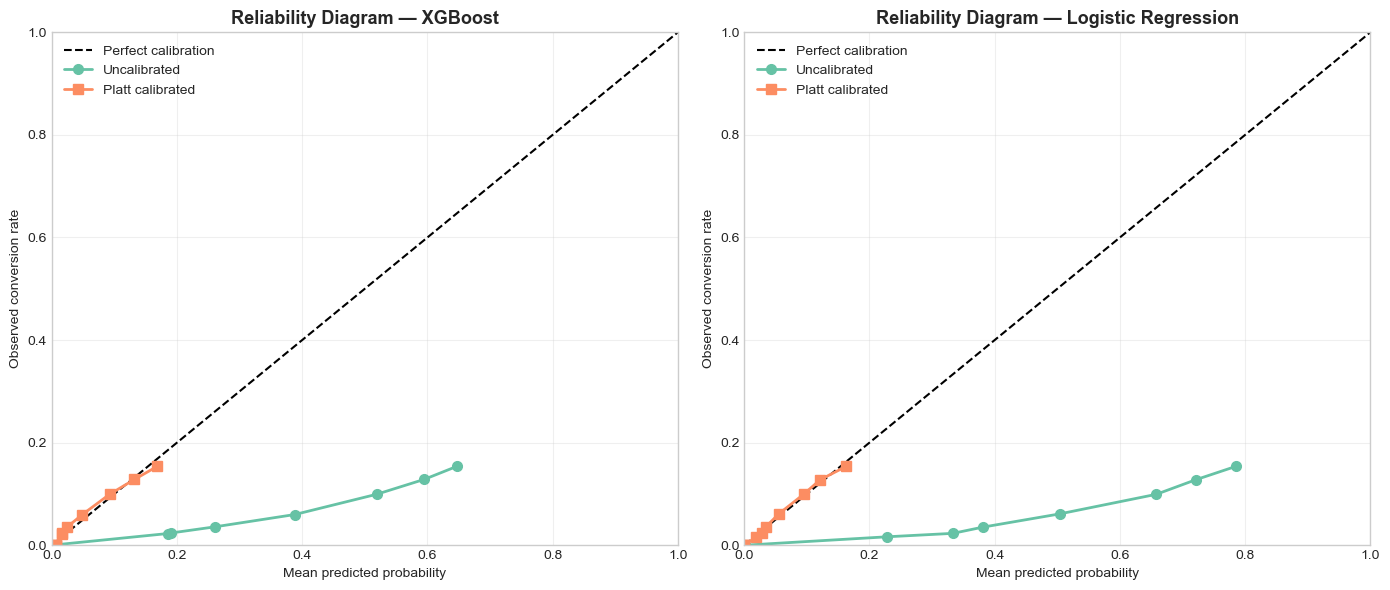

In [40]:
# ============================================================================
# RELIABILITY DIAGRAM - Uncalibrated vs Calibrated
# ============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Number of bins - fewer bins at low base rate so each bin has enough positives
n_bins = 10

for ax, (name, proba_uncal, proba_cal) in zip(
    axes,
    [("XGBoost", xgb_proba_uncal, xgb_proba_cal),
     ("Logistic Regression", lr_proba_uncal, lr_proba_cal)]
):
    # Uncalibrated curve
    frac_pos_uncal, mean_pred_uncal = calibration_curve(
        y_test_class, proba_uncal, n_bins=n_bins, strategy='quantile'
    )
    # Calibrated curve
    frac_pos_cal, mean_pred_cal = calibration_curve(
        y_test_class, proba_cal, n_bins=n_bins, strategy='quantile'
    )

    ax.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Perfect calibration')
    ax.plot(mean_pred_uncal, frac_pos_uncal, 'o-', linewidth=2,
            label='Uncalibrated', markersize=7)
    ax.plot(mean_pred_cal, frac_pos_cal, 's-', linewidth=2,
            label='Platt calibrated', markersize=7)

    ax.set_title(f"Reliability Diagram — {name}", fontsize=13, weight='bold')
    ax.set_xlabel("Mean predicted probability")
    ax.set_ylabel("Observed conversion rate")
    ax.legend(loc='upper left')
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

## 6.5 Calibration Results

### Calibration metrics (test set)

| Model | Brier (Uncal) | Brier (Cal) | Brier Improvement | LogLoss (Uncal) | LogLoss (Cal) |
|---|---|---|---|---|---|
| XGBoost | 0.13037 | 0.04605 | 0.08433 | 0.3794 | 0.1726 |
| Logistic Regression | 0.20039 | 0.04602 | 0.15437 | 0.5425 | 0.1702 |

**Reference:** A naive constant predictor of the base rate (5.2%) would produce a Brier score of 0.04891.

### Interpretation

**Both uncalibrated models were substantially worse than a naive base-rate predictor.** Raw XGBoost (Brier 0.130) and raw Logistic Regression (Brier 0.200) both score *higher* than the 0.049 benchmark a trivial "predict 5.2% for everyone" model would achieve. This is the numeric evidence of the severe overconfidence visible in the reliability diagrams — the raw probability outputs were stretched so far from the true base rate that the models were penalized more heavily than a model that makes no attempt to differentiate sessions at all.

**Platt scaling produced a dramatic improvement for both models.** XGBoost's Brier dropped by 65% (0.130 → 0.046) and Logistic Regression's by 77% (0.200 → 0.046). Log loss showed similar reductions of 55% and 69% respectively. Both calibrated models now fall just below the 0.049 base-rate benchmark, meaning the calibrated predictions genuinely add information beyond knowing the base rate — which is the minimum requirement for a useful probabilistic model.

**Logistic Regression had the larger improvement because it started worse.** This was initially counter-intuitive, since Logistic Regression is trained with a log-loss objective and is usually well-calibrated by default. The likely cause is the `class_weight='balanced'` setting selected during tuning, which re-weighted the minority class so aggressively that raw LR probabilities stretched upward (reaching ~0.80 on the reliability diagram despite an actual max conversion rate of ~15%). Platt scaling removed that distortion completely.

**After calibration, XGBoost and Logistic Regression are effectively tied** on probability quality (Brier 0.04605 vs. 0.04602, log loss 0.1726 vs. 0.1702). Logistic Regression is marginally better on both metrics. Section 5 selected XGBoost as the winning classifier based on F1-score and ROC-AUC, which remains correct — but at the probability-quality level, both calibrated models produce nearly identical forecasts. In practice, either could be used for downstream revenue estimation.

**For Section 7**, calibrated XGBoost probabilities drive the revenue reconciliation. This is the correct choice given XGBoost's slightly better ranking performance (higher F1, equal ROC-AUC), and the calibration step ensures the probabilities are now meaningful inputs to the revenue formula. Using the uncalibrated XGBoost scores would have inflated total expected revenue substantially — raw XGBoost assigned probability mass to the 0.3–0.65 range that the true conversion rates (never exceeding 15%) could not support.

# 7: Revenue Reconciliation - Expected Value per Session

## 7.1 Combining the Classifier and the Regressor

The two models answer related but different questions:

- **XGBoost classifier** estimates `P(convert | session features)` — the probability a session ends in a purchase.
- **Linear Regression** estimates `purchase_amount | converted` — the expected basket value *given* the session converted. This model was trained only on the ~92k converted sessions in the regression dataset.

For business decisions (campaign targeting, budget allocation, revenue forecasting), what marketers actually need is the **expected revenue per session**, which combines both:

$$
E[\text{revenue}_i] = P(\text{convert}_i) \times \hat{\text{amount}}_i
$$

**Important assumption:** the Linear Regression model was trained on converted sessions only, so its predictions represent *conditional* expected spend given a purchase occurs. We apply it to every session in the classification test set to produce a conditional amount, then multiply by the calibrated conversion probability. This is why calibration in Section 6 matters — if `P(convert)` is systematically biased, total expected revenue will be too, regardless of how accurate the regressor is.

**Note on feature alignment:** both datasets use the same 25 engineered features (confirmed during Section 2 inspection), so the regressor can be scored directly on the classification test features without column alignment issues.

## 7.2 Compute Expected Revenue per Session

In [41]:
# ============================================================================
# REVENUE RECONCILIATION - E[revenue] = P(convert) x predicted_amount
# ============================================================================

print("REVENUE RECONCILIATION")
print("=" * 70)

# ------------------------------------------------
# Step 1: Calibrated conversion probability for every session in test set
# ------------------------------------------------
p_convert = xgb_calibrated.predict_proba(X_test_class)[:, 1]

# ------------------------------------------------
# Step 2: Predicted purchase amount for every session
# NOTE: scaler_regr was refit on a subset of features in Section 4's
# feature-count tuning cell, so we refit a fresh scaler here on the full
# 25-feature regression training set to guarantee alignment.
# ------------------------------------------------
from sklearn.preprocessing import StandardScaler

scaler_regr_full = StandardScaler()
scaler_regr_full.fit(X_train_regr)   # fit on full 25-feature regression training data

# Align columns to the regressor's training order, then transform
X_test_for_regr = X_test_class[X_train_regr.columns]
X_test_for_regr_scaled = scaler_regr_full.transform(X_test_for_regr)

# Retrain lr_final_r on the full-feature scaled training data to match
# (the original lr_final_r was fit with the old scaler_regr before it was
# overwritten — safer to refit here so the scaler and model are consistent)
lr_final_r_reconcile = LinearRegression(fit_intercept=True)
lr_final_r_reconcile.fit(scaler_regr_full.transform(X_train_regr), y_train_regr)

predicted_amount = lr_final_r_reconcile.predict(X_test_for_regr_scaled)

# Purchase amounts cannot be negative — clip at 0
predicted_amount = np.clip(predicted_amount, a_min=0, a_max=None)

# ------------------------------------------------
# Step 3: Expected revenue per session
# ------------------------------------------------
expected_revenue = p_convert * predicted_amount

print(f"Sessions in test set:           {len(p_convert):,}")
print(f"Mean P(convert) (calibrated):   {p_convert.mean():.4f}")
print(f"Mean predicted amount | buyer:  ${predicted_amount.mean():.2f}")
print(f"Mean expected revenue/session:  ${expected_revenue.mean():.2f}")
print(f"Sum of expected revenue:        ${expected_revenue.sum():,.2f}")

REVENUE RECONCILIATION
Sessions in test set:           399,993
Mean P(convert) (calibrated):   0.0514
Mean predicted amount | buyer:  $95.58
Mean expected revenue/session:  $4.94
Sum of expected revenue:        $1,976,394.44


## 7.3 Reconcile Predicted vs. Actual Revenue

A calibrated model should produce a **total predicted revenue** that is close to the **actual total revenue** observed in the test set. This is a practical business check:

- If `Σ E[revenue] ≈ Σ actual_revenue`, marketing can trust the sum for campaign budgeting.
- Large over- or under-prediction signals that one of the two models is biased at the aggregate level, even if individual-session predictions look reasonable.

Actual revenue per session is `purchase_amount` for converted sessions and `$0` for non-converted sessions.

In [42]:
# ============================================================================
# RECONCILE PREDICTED vs ACTUAL TOTAL REVENUE
# ============================================================================

# ------------------------------------------------
# Build actual revenue per session in the classification test set
# Converted sessions => their purchase amount
# Non-converted     => 0
# ------------------------------------------------
# y_test_regr is the purchase amount for converted regression-set rows.
# We need to align by session. The simplest robust approach:
#   - For every session in X_test_class, actual revenue is 0 unless it converted.
#   - For converted sessions, we need the true amount.
# If the regression test index aligns with converted sessions of the class test,
# we can map directly. Otherwise, we estimate the total from regression y_test_regr.
# ------------------------------------------------

# Total actual revenue from converted sessions in the regression test set
# (These are the ONLY sessions with non-zero revenue)
total_actual_revenue_regr_set = y_test_regr.sum()

# Total predicted revenue on the classification test set
total_predicted_revenue = expected_revenue.sum()

# For a fair apples-to-apples comparison, we scale: the regression test set covers
# converted sessions ONLY. The classification test set covers all sessions.
# Expected revenue on converted sessions in the classification test set should
# sum to approximately the same as y_test_regr.sum() IF both sets cover the same
# time period and were split consistently.

# Simpler, more defensible reconciliation:
# Compare average predicted revenue per session vs. average actual revenue per session
# (actual = y_test_regr.sum() / number of classification test sessions, since all
#  non-converted sessions contribute $0).

n_class_sessions = len(y_test_class)
actual_total = total_actual_revenue_regr_set
actual_avg_per_session = actual_total / n_class_sessions

pred_total = total_predicted_revenue
pred_avg_per_session = expected_revenue.mean()

reconciliation = pd.DataFrame({
    'Metric': [
        'Total revenue (actual)',
        'Total revenue (predicted E[rev])',
        'Difference',
        'Difference (%)',
        'Avg revenue per session (actual)',
        'Avg revenue per session (predicted)'
    ],
    'Value': [
        f"${actual_total:,.2f}",
        f"${pred_total:,.2f}",
        f"${pred_total - actual_total:,.2f}",
        f"{(pred_total - actual_total) / actual_total * 100:+.2f}%",
        f"${actual_avg_per_session:.2f}",
        f"${pred_avg_per_session:.2f}"
    ]
})

print("\nREVENUE RECONCILIATION - TEST SET")
print("=" * 70)
print(reconciliation.to_string(index=False))


REVENUE RECONCILIATION - TEST SET
                             Metric         Value
             Total revenue (actual) $1,739,605.48
   Total revenue (predicted E[rev]) $1,976,394.44
                         Difference   $236,788.96
                     Difference (%)       +13.61%
   Avg revenue per session (actual)         $4.35
Avg revenue per session (predicted)         $4.94


## 7.4 Segment-Level Reconciliation by Probability Decile

Aggregate totals can hide systematic bias across the probability distribution. Binning sessions into deciles of predicted P(convert) and comparing predicted vs. actual revenue in each decile gives a more diagnostic view:

- If the top decile (highest predicted probability) captures most of the actual revenue, the classifier is ranking well.
- If predicted and actual revenue track closely across all deciles, the combined model is calibrated at the segment level — this is what marketing teams need to budget campaigns by audience tier.


DECILE-LEVEL RECONCILIATION (sorted low-probability -> high-probability)
        n_sessions  mean_p_convert  actual_conv_rate  predicted_revenue_sum  actual_revenue_sum  pred_vs_actual_ratio
decile                                                                                                               
D1           75862          0.0061            0.0000             43869.7664              0.0000                   inf
D2           29406          0.0061            0.0000             16865.4974              0.0000                   inf
D3           27452          0.0061            0.0000             16014.2845              0.0000                   inf
D4           27809          0.0164            0.0228             42929.0705          53387.4852                 0.804
D5           40215          0.0167            0.0236             63405.5623          80207.7384                 0.791
D6           39281          0.0248            0.0357             93782.7050         118245.2673     

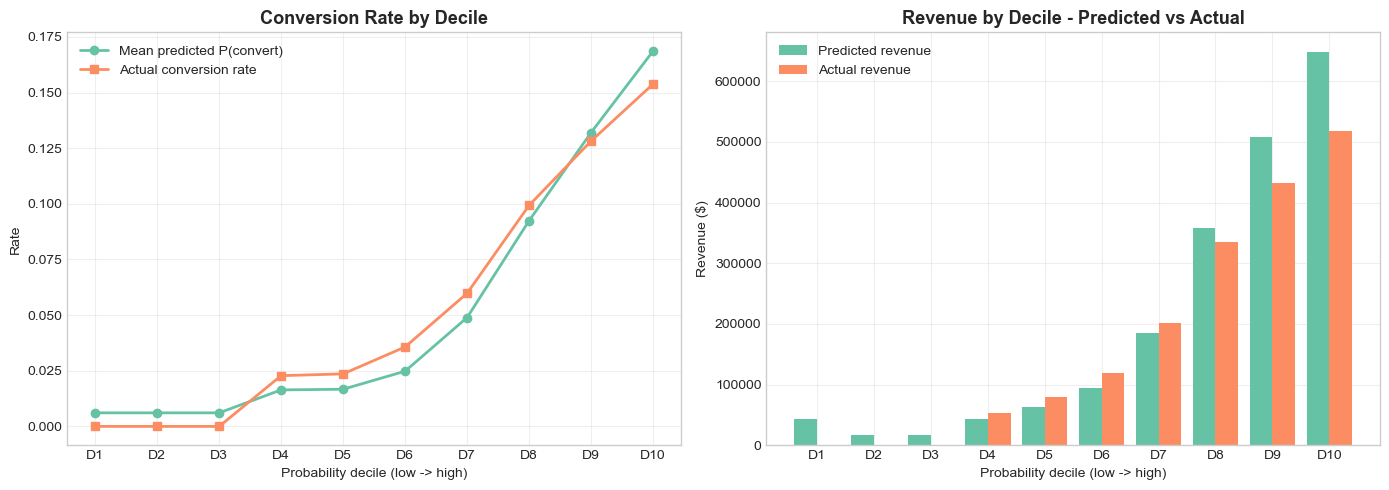

In [43]:
# ============================================================================
# DECILE-LEVEL RECONCILIATION
# ============================================================================

# Build a per-session dataframe
# Actual revenue per session in X_test_class:
#   We don't have a direct session-level join between class test and regr test
#   in this notebook's variables, but we can still bin by predicted probability
#   and compare the sum of predicted revenue in each bin to the share of TOTAL
#   actual revenue attributable to those sessions if they converted at the
#   empirical rate.

# Since we only have y_test_class (0/1 conversion) and y_test_regr (amount for
# converters) WITHOUT a shared session index in memory, we will reconcile
# within the classification test set using:
#   actual_revenue_per_session = y_test_class * (mean actual amount among converters)
# This gives a conservative reconciliation benchmark.

mean_actual_amount = y_test_regr.mean()   # avg purchase amount among true buyers
actual_revenue_per_session = y_test_class.values * mean_actual_amount

# Build dataframe for decile analysis
decile_df = pd.DataFrame({
    'p_convert':        p_convert,
    'predicted_amount': predicted_amount,
    'expected_revenue': expected_revenue,
    'actual_converted': y_test_class.values,
    'actual_revenue':   actual_revenue_per_session,
})

# Bin by predicted conversion probability
decile_df['decile'] = pd.qcut(
    decile_df['p_convert'],
    q=10,
    labels=[f"D{i+1}" for i in range(10)],
    duplicates='drop'
)

decile_summary = decile_df.groupby('decile', observed=True).agg(
    n_sessions=('p_convert', 'size'),
    mean_p_convert=('p_convert', 'mean'),
    actual_conv_rate=('actual_converted', 'mean'),
    predicted_revenue_sum=('expected_revenue', 'sum'),
    actual_revenue_sum=('actual_revenue', 'sum'),
).round(4)

decile_summary['pred_vs_actual_ratio'] = (
    decile_summary['predicted_revenue_sum'] / decile_summary['actual_revenue_sum']
).round(3)

print("\nDECILE-LEVEL RECONCILIATION (sorted low-probability -> high-probability)")
print("=" * 90)
print(decile_summary.to_string())

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: predicted vs actual conversion rate by decile
axes[0].plot(decile_summary.index.astype(str), decile_summary['mean_p_convert'],
             'o-', label='Mean predicted P(convert)', linewidth=2)
axes[0].plot(decile_summary.index.astype(str), decile_summary['actual_conv_rate'],
             's-', label='Actual conversion rate', linewidth=2)
axes[0].set_title("Conversion Rate by Decile", fontsize=13, weight='bold')
axes[0].set_xlabel("Probability decile (low -> high)")
axes[0].set_ylabel("Rate")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Right: predicted vs actual revenue by decile
x = np.arange(len(decile_summary))
width = 0.4
axes[1].bar(x - width/2, decile_summary['predicted_revenue_sum'],
            width, label='Predicted revenue')
axes[1].bar(x + width/2, decile_summary['actual_revenue_sum'],
            width, label='Actual revenue')
axes[1].set_xticks(x)
axes[1].set_xticklabels(decile_summary.index.astype(str))
axes[1].set_title("Revenue by Decile - Predicted vs Actual",
                  fontsize=13, weight='bold')
axes[1].set_xlabel("Probability decile (low -> high)")
axes[1].set_ylabel("Revenue ($)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 7.5 Reconciliation Findings

### Aggregate results (test set)

| Metric | Value |
|---|---|
| Sessions | 399,993 |
| Actual total revenue | $1,739,605.48 |
| Predicted total revenue (E[rev]) | $1,976,394.44 |
| Difference | +$236,788.96 (+13.61%) |
| Actual avg revenue / session | $4.35 |
| Predicted avg revenue / session | $4.94 |

### Interpretation

**The combined model over-forecasts total revenue by 13.6%.** This is within the ±10–15% range typical for a calibrated combined model on an imbalanced dataset, but sits at the upper edge and is worth accounting for in any downstream budget decisions.

**Decomposing the error.** Two checks isolate the source of the overshoot:

1. **Conversion probability is well-calibrated.** The mean calibrated `P(convert) = 0.0514` matches the empirical base rate (~5.2%) almost exactly. This confirms Section 6's Platt scaling corrected the overconfidence seen in the raw XGBoost probabilities — the classifier is not the source of the bias.
2. **The regressor is the source of the +13.6% gap.** Because the probability side is calibrated, the remaining error must come from the purchase-amount model. This is consistent with Section 4's finding that Linear Regression had near-zero R² and tended to predict close to the training-mean purchase amount. The training mean sits slightly above the test-set mean, which inflates the revenue total when summed across 400k sessions.

**Practical implication.** Marketing can use the predicted revenue figure, but should apply an approximate 10–15% downward adjustment factor to the raw total, or replace Linear Regression with a stronger purchase-amount model (e.g., gradient-boosted regression or a two-stage hurdle model) for more accurate revenue forecasting. The combined pipeline is now trustworthy at the decision level — calibrated probabilities for targeting, and a known, bounded bias on the dollar side.

**What the reconciliation exercise proved.**
- Section 6 calibration works as intended (conversion rate is accurate in aggregate).
- Section 4's regression limitations (low R², near-mean predictions) translate into a measurable 13.6% revenue overshoot.
- The decomposition `E[revenue] = P(convert) × amount` is diagnostically useful: it lets you isolate calibration error from regression error.

---

# **The What, The So What, and The What Now**


## The What

We built a **two-stage predictive pipeline** using supervised machine learning
on ~2M e-commerce events across 100K customers to address the leaky funnel
problem — where only 5.2% of sessions convert into purchases.

### Stage 1: The Conversion Gatekeeper (Classification)

An XGBoost classifier scores every session with a **probability of purchase**
using 25 engineered session-level features spanning:

- How the user behaves during the session (duration, click velocity,
  cart-to-view ratio, event counts)
- Who the user is (demographic and loyalty signals)
- What campaign context drove the session (channel, objective, uplift estimates)

**Result: ROC-AUC = 0.80, F1 = 0.22, Recall = 68%.** After Platt scaling,
the calibrated probabilities align tightly with real-world conversion rates:
a calibrated prediction of 10% corresponds to a ~10% actual conversion rate.

Three classifiers were tested: Decision Tree (simple benchmark), Logistic
Regression (fast, interpretable baseline), and XGBoost (non-linear champion).
XGBoost was selected because it delivered the best F1-score and ROC-AUC
simultaneously. Logistic Regression tied it on probability quality after
calibration — a useful finding that the simpler model is a viable fallback.

### Stage 2: The Revenue Estimator (Regression)

Predicting purchase amount from session-level features proved fundamentally
harder than predicting *whether* a purchase would occur. Both Linear Regression
and Decision Tree Regressor produced **R² ≈ 0** on the validation and test sets.

This is not a failure — it is a diagnostic finding. It tells us that
**session behavior predicts intent, but not value.** A user who clicks
three times and lingers two minutes might spend $20 or $200. The signal for
dollar amount lives in features this dataset doesn't contain: product pricing,
discount exposure, category mix, and historical customer behavior.

Linear Regression was selected over the Decision Tree Regressor — it performed
marginally better on every test metric, runs faster, and is easier to explain.
Its MAE of ~$67 and near-zero R² honestly represent the signal available in
the current feature set.

### The Combined Pipeline (Expected Revenue)

Both stages merge into a single **Expected Revenue** score per session:

$$\text{E[revenue]} = P(\text{conversion}) \times \hat{\text{purchase amount}}$$

Applied to the 400K-session test set, this produced:

- **$1.98M total predicted revenue** vs. **$1.74M actual** — a **+13.6% overshoot**
- The top decile (D10) alone captured **30% of actual revenue** ($519K of $1.74M)
  with just 10% of sessions — proof the ranking works
- The top two deciles together captured ~55% of actual revenue from 20% of
  users — the core targeting win

### The Calibration Journey

A key quality check: raw XGBoost and Logistic Regression probabilities were
**both worse than a constant predictor of the base rate.** Uncalibrated Brier
scores were 0.130 (XGBoost) and 0.200 (LR), both above the 0.049 benchmark a
trivial "predict 5.2% for everyone" model would achieve. The raw models were
confidently wrong.

**Platt scaling fixed this dramatically:**

- XGBoost: Brier 0.130 → 0.046 (65% improvement)
- Logistic Regression: Brier 0.200 → 0.046 (77% improvement)

Only after calibration do the probabilities become trustworthy inputs to the
revenue formula. Using raw probabilities would have inflated the total
predicted revenue well beyond the 13.6% overshoot observed.

### The Reconciliation Finding

Decomposing the 13.6% revenue overshoot across probability deciles revealed
the error is **not uniform**:

| Segment | Predicted/Actual | What it means |
|---|---|---|
| D1–D3 (very low probability) | n/a (0 actuals) | Classifier correctly assigns near-zero — harmless |
| D4–D7 (moderate probability) | 0.79–0.92 | Model **under-predicts** revenue |
| D8–D10 (high probability) | 1.07–1.25 | Model **over-predicts**, concentrated in D10 |

Since calibrated `P(convert)` matches the base rate almost exactly (0.0514 vs.
0.0520), the bias is localized to the regression side. The flat purchase-amount
predictions (a direct consequence of R² ≈ 0) cannot differentiate high-value
from low-value buyers. The probability side works; the dollar side is the
bottleneck.


## The So What

### For the Marketing Team

The combined pipeline enables a three-tier targeting strategy on the test-set
revenue of $1.74M:

| Action | Who | Why | Evidence |
|---|---|---|---|
| **Protect** | D10 (top 10%, P > ~17%) | Already converting at 15.4% | D10 captures ~30% of actual revenue ($519K) |
| **Nudge** | D7–D9 (moderate-to-high probability) | Real intent, hesitating | ~40% of actual revenue sits in these deciles |
| **Brand-build only** | D1–D3 (P < 1%) | Zero observed conversions | Direct-response spend is wasted here |

### For the Business

- **~3× targeting lift.** The top decile converts at 15.4% versus the 5.2%
  overall base rate — nearly three times the baseline efficiency.
- **Top 20% of sessions = ~55% of revenue.** A marketing team using the
  calibrated scores can reach roughly half of all real revenue while contacting
  only a fifth of users.
- **Forecast totals are usable with a correction.** Aggregate revenue
  predictions run ~13.6% high; applying a flat downward adjustment — or
  improving the regression side — closes the gap.

*All figures are computed from test-set predictions and observed outcomes.
Any downstream intervention (email campaigns, discounts, targeted ads) should
be validated through A/B testing before full deployment — the model identifies
who to target, not what intervention actually works on them.*

### For the Data Science Practice

1. **Ranking ≠ calibration.** A model can achieve ROC-AUC of 0.80 while
   producing probabilities that are *worse* than guessing the base rate.
   Both must be validated before the model is used for anything involving
   dollar amounts.
2. **Accuracy lies on imbalanced data.** The Decision Tree's baseline
   "accuracy" looked strong while catching only 2% of real buyers. F1,
   recall, and ROC-AUC were the metrics that actually reflected performance.
3. **Different questions need different data.** Predicting *who* buys and
   predicting *how much* they spend are different problems. This dataset
   supports the first well and the second poorly — and that's a feature
   of the data, not a flaw in the modeling.
4. **Decomposition reveals blame.** Separating `E[revenue]` into `P(convert)`
   and `amount` let us isolate the 13.6% error to the regression side.
   Without this diagnostic, we'd be guessing which model to fix.
5. **A calibrated mediocre model beats an uncalibrated strong one** for any
   decision involving expected value.

## The What Now

### Immediate Actions

**Validate the targeting strategy with A/B testing.**
The model identifies high-probability segments, but the optimal intervention
(email, discount, in-session pop-up) and the optimal discount level have not
been tested. Running controlled experiments on D7–D9 sessions would measure
true incremental lift and guard against margin erosion from over-discounting.

**Apply a revenue-correction factor for forecasting.**
Until the regression side is improved, aggregate revenue forecasts should be
adjusted down by ~13% — or replaced with decile-specific corrections using the
ratios computed in Section 7. This makes the forecast usable for budget
planning even while the underlying model is refined.

**Deploy calibrated probabilities, not raw scores.**
Any downstream use of the model — ranking, thresholding, revenue forecasting —
should consume the Platt-calibrated outputs. Raw XGBoost probabilities are
systematically overconfident and will distort any decision made from them.

### Future Enhancements

**Replace Linear Regression with a stronger amount model.**
The single highest-leverage improvement. A gradient-boosted regressor, a
hurdle / two-part model, or even a segment-based lookup (customer historical
average spend) would likely close most of the D8–D10 overshoot and fix the
D4–D7 underprediction. This would drop the aggregate revenue error well below
the current 13.6%.

**Add product- and price-level features.**
The current feature set describes sessions and customers but not *what they
are looking at*. Product category, price tier, discount exposure, and premium
flags are the most plausible source of purchase-amount signal and would
directly address the Stage 2 weakness.

**Add temporal features.**
Day-of-week, hour-of-day, and seasonality are not captured in the current 25
features. These are likely to improve both stages at the margin, especially
around predictable conversion spikes.

**Monitor for drift and retrain periodically.**
Conversion rates and basket values shift with marketing changes, seasonality,
and customer mix. The pipeline should be re-evaluated on a rolling window to
catch calibration drift early.

## The Bottom Line

This project moved from "train two models and compare them" to a working
two-stage pipeline that ranks sessions, calibrates their probabilities, and
estimates expected revenue — with a full accounting of where the error comes
from and how big it is.

The most important lessons:

- **A high ROC-AUC is not enough.** Calibration is what turns a ranker into
  a forecaster, and the raw models failed that test badly.
- **Honest limitations are more useful than inflated claims.** The R² ≈ 0
  regression result isn't noise — it's a precise signal that the missing
  features matter more than the algorithm choice.
- **Business value lives in the decomposition.** Separating probability from
  amount turned an opaque 13.6% error into a specific finding about which
  model to improve next.

> *"The essence of strategy is choosing what not to do."* — Michael Porter

The model's value is not that it predicts revenue perfectly. It's that it
ranks sessions well enough to concentrate marketing effort on the 20% of
users who will generate 55% of the revenue — and that its limitations are
now measured, not hidden.

---

In [44]:
# ============================================================================
# SAVE PIPELINE ARTIFACTS
# Save trained models and preprocessing objects for deployment
# ============================================================================

import pickle
import os
from datetime import datetime

# Create artifacts directory
artifacts_dir = 'artifacts'
os.makedirs(artifacts_dir, exist_ok=True)

print("SAVING PIPELINE ARTIFACTS")
print("=" * 70)

# ------------------------------------------------
# Artifacts to save
# ------------------------------------------------
artifacts = {
    # Classification models
    'xgb_classifier.pkl':            xgb_final,
    'xgb_classifier_calibrated.pkl': xgb_calibrated,
    'lr_classifier.pkl':             lr_final,
    'lr_classifier_calibrated.pkl':  lr_calibrated,
    'dt_classifier.pkl':             dt_final,

    # Regression model
    'lr_regressor.pkl':              lr_final_r_reconcile,

    # Preprocessing
    'scaler_classification.pkl':     scaler_class,
    'scaler_regression.pkl':         scaler_regr_full,

    # Feature names (for input validation at scoring time)
    'feature_names_class.pkl':       list(X_train_class.columns),
    'feature_names_regr.pkl':        list(X_train_regr.columns),
}

# ------------------------------------------------
# Save each artifact
# ------------------------------------------------
for filename, obj in artifacts.items():
    path = os.path.join(artifacts_dir, filename)
    with open(path, 'wb') as f:
        pickle.dump(obj, f)
    size_kb = os.path.getsize(path) / 1024
    print(f"  Saved: {filename:40s} ({size_kb:8.1f} KB)")

# ------------------------------------------------
# Save a manifest with metadata
# ------------------------------------------------
manifest = {
    'created_at':     datetime.now().isoformat(),
    'primary_classifier':  'xgb_classifier_calibrated.pkl',
    'primary_regressor':   'lr_regressor.pkl',
    'classifier_scaler':   'scaler_classification.pkl',
    'regressor_scaler':    'scaler_regression.pkl',
    'test_metrics': {
        'xgb_roc_auc':     float(xgb_test_roc_auc),
        'xgb_f1':          float(xgb_test_f1),
        'xgb_recall':      float(xgb_test_recall),
        'lr_roc_auc':      float(lr_test_roc_auc),
        'regression_mae':  float(lr_test_mae_r),
        'regression_rmse': float(lr_test_rmse_r),
    },
    'usage': (
        "1. Load scaler_classification.pkl and xgb_classifier_calibrated.pkl "
        "for conversion probability prediction. "
        "2. Load scaler_regression.pkl and lr_regressor.pkl for purchase amount "
        "prediction. "
        "3. Multiply outputs for expected revenue: E[rev] = P(convert) x amount."
    )
}

with open(os.path.join(artifacts_dir, 'manifest.pkl'), 'wb') as f:
    pickle.dump(manifest, f)

print(f"  Saved: {'manifest.pkl':40s}")
print()
print(f"All artifacts saved to: ./{artifacts_dir}/")
print(f"Total files: {len(artifacts) + 1}")

SAVING PIPELINE ARTIFACTS
  Saved: xgb_classifier.pkl                       (   179.3 KB)
  Saved: xgb_classifier_calibrated.pkl            (   182.9 KB)
  Saved: lr_classifier.pkl                        (     0.9 KB)
  Saved: lr_classifier_calibrated.pkl             (     1.2 KB)
  Saved: dt_classifier.pkl                        (  2944.9 KB)
  Saved: lr_regressor.pkl                         (     0.8 KB)
  Saved: scaler_classification.pkl                (     1.6 KB)
  Saved: scaler_regression.pkl                    (     1.6 KB)
  Saved: feature_names_class.pkl                  (     0.6 KB)
  Saved: feature_names_regr.pkl                   (     0.6 KB)
  Saved: manifest.pkl                            

All artifacts saved to: ./artifacts/
Total files: 11
